In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import skew, kurtosis, uniform
from sklearn.preprocessing import PowerTransformer # for performing "yeo-johnson0" transformation
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.impute import KNNImputer
from category_encoders import BinaryEncoder # BinaryEncoder for binary categorical features
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV

In [5]:
df = pd.read_csv("AmesHousing.csv")

# Printing first 5 records of the dataset
print(df.head(5))

   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  Alley Lot Shape Land Contour  ... Pool Area Pool QC  Fence Misc Feature  \
0   NaN       IR1          Lvl  ...         0     NaN    NaN          NaN   
1   NaN       Reg          Lvl  ...         0     NaN  MnPrv          NaN   
2   NaN       IR1          Lvl  ...         0     NaN    NaN         Gar2   
3   NaN       Reg          Lvl  ...         0     NaN    NaN          NaN   
4   NaN       IR1          Lvl  ...         0     NaN  MnPrv          NaN   

  Misc Val Mo Sold Yr Sold Sale Type  Sale Condition  SalePrice  
0       

In [6]:
# to check for which column has null values
df.isnull().sum()

Order               0
PID                 0
MS SubClass         0
MS Zoning           0
Lot Frontage      490
                 ... 
Mo Sold             0
Yr Sold             0
Sale Type           0
Sale Condition      0
SalePrice           0
Length: 82, dtype: int64

In [7]:
# Drop a column  if it has a large percentage of missing data (threshhold 0.7)
threshhold = 0.70
missing = df.isnull().mean()
print(missing)

df.drop(columns = missing[missing > threshhold].index, inplace=True)
print(df.head(5))

Order             0.000000
PID               0.000000
MS SubClass       0.000000
MS Zoning         0.000000
Lot Frontage      0.167235
                    ...   
Mo Sold           0.000000
Yr Sold           0.000000
Sale Type         0.000000
Sale Condition    0.000000
SalePrice         0.000000
Length: 82, dtype: float64
   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  Lot Shape Land Contour Utilities  ... Enclosed Porch 3Ssn Porch  \
0       IR1          Lvl    AllPub  ...              0          0   
1       Reg          Lvl    AllPub  ...              0          0   
2     

In [8]:
# New regression focus: predict the original construction year ("Year Built")
# drop rows with missing target values because they won't contribute to any learning
df.dropna(subset = ["Year Built"], inplace=True)

# Feature engineering: use remodeling delta instead of the raw remodel year.
# This captures "years between build and last remodel" without leaking raw calendar years.
df["Year Remod/Add Delta"] = df["Year Remod/Add"] - df["Year Built"]

# Drop columns to avoid data leakage / irrelevant temporal information:
#  - SalePrice      : price must not be used in this regression
#  - House Style    : target variable of the classification task (leakage)
#  - Year Remod/Add : replaced by the engineered "Year Remod/Add Delta"
#  - Yr Sold/Mo Sold: transaction time, not a property characteristic
df.drop(columns=["SalePrice", "House Style", "Year Remod/Add", "Yr Sold", "Mo Sold"], inplace=True)
print(df.head(5))


   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  Lot Shape Land Contour Utilities  ... Wood Deck SF Open Porch SF  \
0       IR1          Lvl    AllPub  ...          210            62   
1       Reg          Lvl    AllPub  ...          140             0   
2       IR1          Lvl    AllPub  ...          393            36   
3       Reg          Lvl    AllPub  ...            0             0   
4       IR1          Lvl    AllPub  ...          212            34   

  Enclosed Porch 3Ssn Porch Screen Porch Pool Area  Misc Val  Sale Type  \
0              0          0            0 

### Feature Engineering & Leakage Prevention

For the construction-year regression, the cell above performs two important steps:

**Engineered feature**
- `Year Remod/Add Delta = Year Remod/Add − Year Built` — the number of years between original construction and the most recent remodel. This captures *renovation recency* without leaking a raw calendar year into the model.

**Columns dropped to prevent leakage / irrelevance**
- `SalePrice` — price must not be used; the task is independent of market valuation.
- `House Style` — this is the **target of the separate classification task**; including it would leak the answer (e.g. "2Story" strongly implies a modern era).
- `Year Remod/Add` — replaced by the engineered delta so no raw remodel year remains.
- `Yr Sold` / `Mo Sold` — these describe *when the sale happened*, not a physical property of the house, and could introduce temporal artefacts.

The target `Year Built` is kept in its original calendar-year scale throughout.


# Exploratory Data Analysis: Target Variable (Year Built)

Before preprocessing, we explore the target variable `Year Built` and how it relates to the predictors.

- **Distribution:** the histogram and boxplot below show how construction years are spread across the dataset. The distribution is **left-skewed** — there are more recently built homes than very old ones — and ranges roughly from the late 1800s to 2010.
- **Relationships with predictors:** the correlation bar chart ranks how strongly each numerical feature moves with construction year, and the scatter plots illustrate the strongest relationships (e.g. `Garage Yr Blt`, `Overall Qual`). These confirm that physical/quality features carry a real signal about when a house was built, which is exactly what the regression models will exploit.


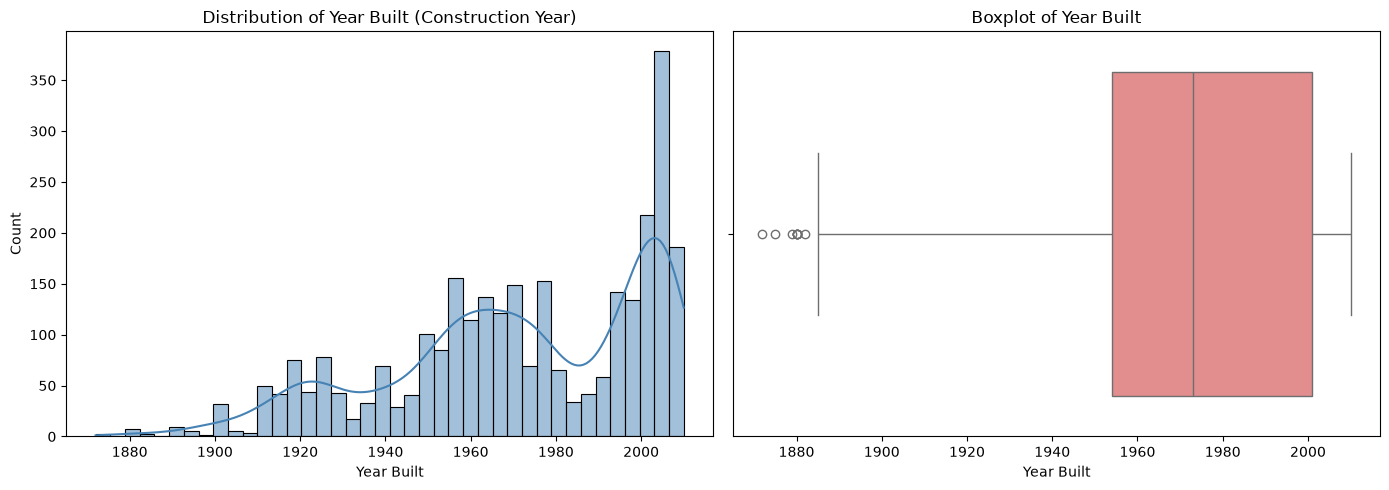

count    2930.000000
mean     1971.356314
std        30.245361
min      1872.000000
25%      1954.000000
50%      1973.000000
75%      2001.000000
max      2010.000000
Name: Year Built, dtype: float64

Skewness: -0.604  (negative = left-skewed, more newer homes)
Kurtosis: -0.502


In [9]:
# Distribution of the target variable: Year Built
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Year Built'], bins=40, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Distribution of Year Built (Construction Year)')
axes[0].set_xlabel('Year Built')

sns.boxplot(x=df['Year Built'], color='lightcoral', ax=axes[1])
axes[1].set_title('Boxplot of Year Built')
axes[1].set_xlabel('Year Built')

plt.tight_layout()
plt.show()

# Summary statistics for the target
print(df['Year Built'].describe())
print(f"\nSkewness: {df['Year Built'].skew():.3f}  (negative = left-skewed, more newer homes)")
print(f"Kurtosis: {df['Year Built'].kurtosis():.3f}")


C:\Users\A01411\AppData\Local\Temp\ipykernel_39000\2216435582.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr_with_target.values, y=corr_with_target.index, palette='coolwarm')


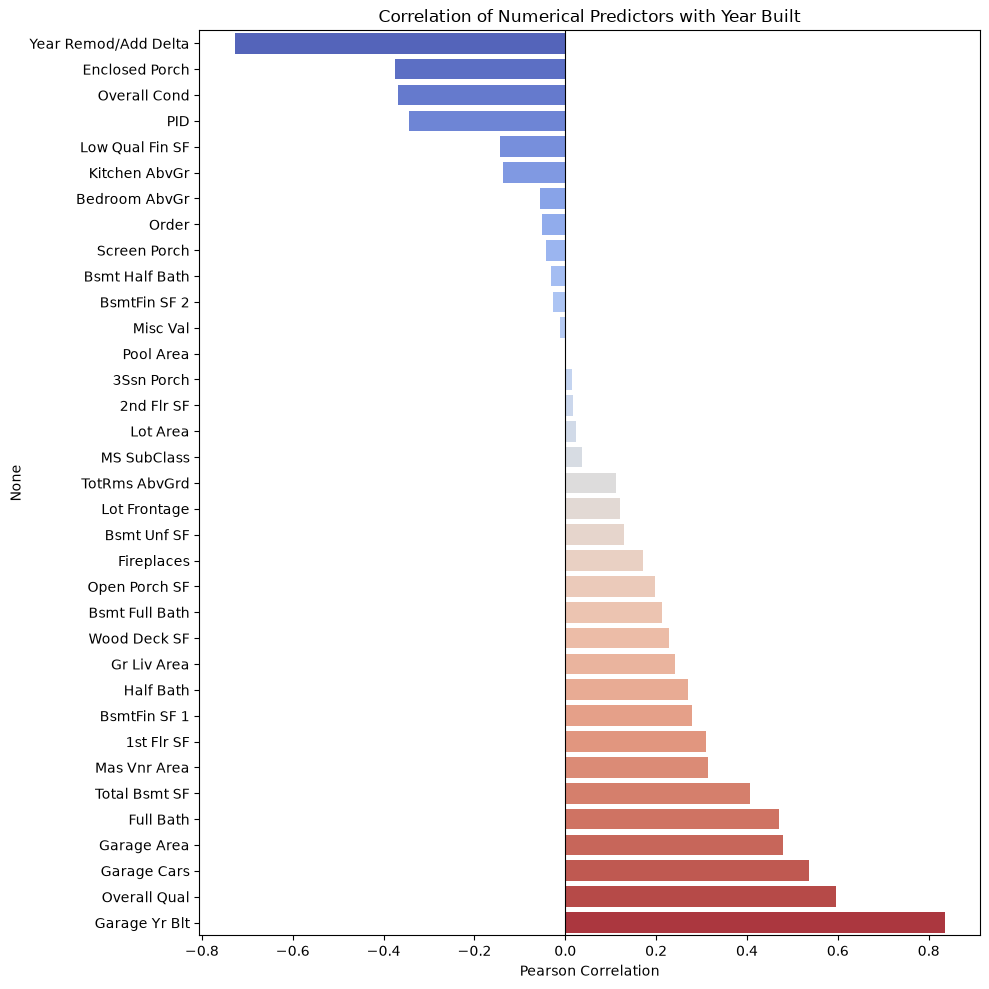

Strongest POSITIVE correlations with Year Built (newer homes):
Garage Yr Blt    0.834849
Overall Qual     0.597027
Garage Cars      0.537443
Garage Area      0.480131
Full Bath        0.469406
Total Bsmt SF    0.407526
Mas Vnr Area     0.313292
1st Flr SF       0.310463
Name: Year Built, dtype: float64

Strongest NEGATIVE correlations with Year Built (older homes):
Year Remod/Add Delta   -0.727220
Enclosed Porch         -0.374364
Overall Cond           -0.368773
PID                    -0.343388
Low Qual Fin SF        -0.144282
Kitchen AbvGr          -0.137852
Bedroom AbvGr          -0.055093
Order                  -0.052319
Name: Year Built, dtype: float64


In [ ]:
# Correlation of numerical predictors with the target (Year Built)
num_features = df.select_dtypes(include=['float64', 'int64'])
corr_with_target = num_features.corr(numeric_only=True)['Year Built'].drop('Year Built').sort_values()

plt.figure(figsize=(10, 10))
colors = ['red' if x < 0 else 'green' for x in corr_with_target.values]
sns.barplot(x=corr_with_target.values, y=corr_with_target.index, palette=colors)
plt.title('Correlation of Numerical Predictors with Year Built')
plt.xlabel('Pearson Correlation')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

print("Strongest POSITIVE correlations with Year Built (newer homes):")
print(corr_with_target.tail(8)[::-1])
print("\nStrongest NEGATIVE correlations with Year Built (older homes):")
print(corr_with_target.head(8))


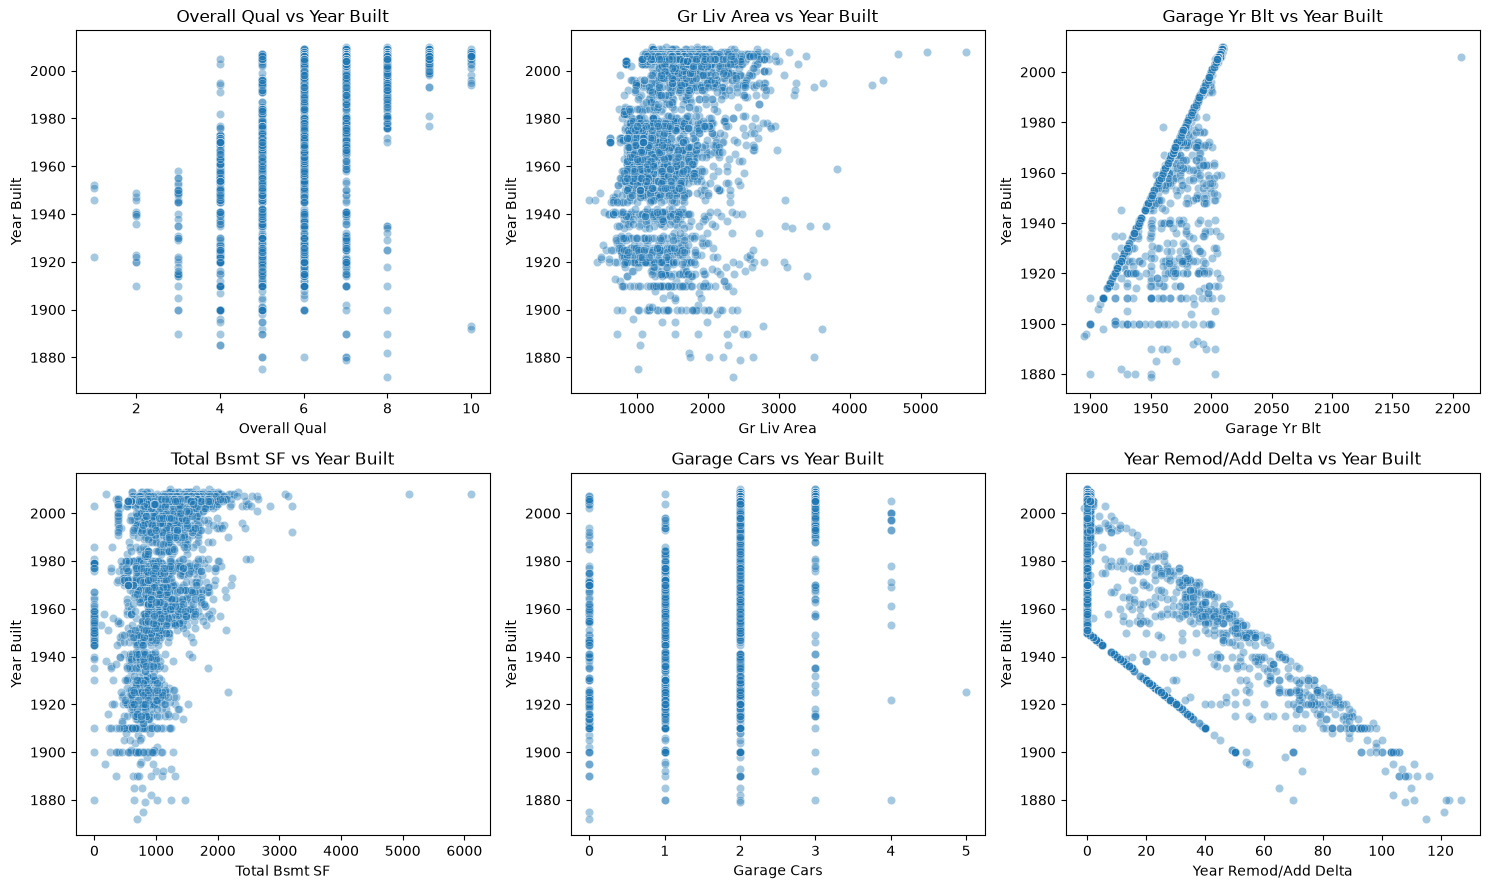

In [11]:
# Relationships between key predictors and the target (Year Built)
key_predictors = ['Overall Qual', 'Gr Liv Area', 'Garage Yr Blt', 'Total Bsmt SF', 'Garage Cars', 'Year Remod/Add Delta']

plt.figure(figsize=(15, 9))
for i, col in enumerate(key_predictors, 1):
    plt.subplot(2, 3, i)
    sns.scatterplot(x=df[col], y=df['Year Built'], alpha=0.4)
    plt.xlabel(col)
    plt.ylabel('Year Built')
    plt.title(f'{col} vs Year Built')
plt.tight_layout()
plt.show()


# Data Preprocessing

The raw Ames data needs several cleaning and transformation steps before it can be fed to the regression models that predict **Year Built**. The full preprocessing workflow is applied in the sections below, in this order:

**1. Dropping sparse columns** — Columns with more than 70% missing values are removed, since they carry too little information to impute reliably.

**2. Target row filtering** — Rows with a missing `Year Built` (the target) are dropped, because they cannot be used for supervised learning.

**3. Feature engineering & leakage removal** — `Year Remod/Add Delta` is created, and `SalePrice`, `House Style`, `Year Remod/Add`, `Yr Sold`, and `Mo Sold` are dropped (see the note above).

**4. Missing value imputation**
- *Numerical features:* KNN imputation (k=5, distance-weighted) for related numeric gaps, followed by mean/median fill based on each feature's skewness (median when highly skewed, mean otherwise).
- *Categorical features:* mode imputation where a single category dominates, and an explicit `"Unknown"` category where missingness is high (e.g. `Fireplace Qu`).

**5. Outlier handling (IQR method)** — For every numerical predictor, outliers beyond 1.5×IQR are either removed (few outliers) or capped to the bounds (many outliers). The target `Year Built` is deliberately **excluded** so its true labels are never altered.

**6. Transformations** — Skewed predictors are normalised: log transform for highly right-skewed features, square-root for moderate right-skew, and Yeo-Johnson for left-skewed features. The target `Year Built` is **not** transformed and stays in calendar-year units.

**7. Scaling & encoding (inside a `ColumnTransformer` pipeline)**
- `StandardScaler` for approximately normal numeric features.
- `MinMaxScaler` for skewed numeric features.
- `OrdinalEncoder` for ordered quality/condition ratings (e.g. `Exter Qual`, `Kitchen Qual`).
- `OneHotEncoder` for nominal categories.
- `BinaryEncoder` for high-cardinality categories (e.g. `Neighborhood`).

This pipeline guarantees the same transformations are applied consistently to both the training and test sets.


Visualization for detecting normal distribution of each features

In [12]:
# list of all columns that contains null values
lst_null_values = df.columns[df.isnull().any()].tolist()
print(lst_null_values)

"""
# dictionary of all null values along with their column names
# Get columns with their number of missing values
null_values = df.isnull().sum()

# columns with missing values
columns_with_null = {col: null_values[col] for col in df.columns if null_values[col] > 0}
print(columns_with_null)"""

['Lot Frontage', 'Mas Vnr Type', 'Mas Vnr Area', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Electrical', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Cars', 'Garage Area', 'Garage Qual', 'Garage Cond']


'\n# dictionary of all null values along with their column names\n# Get columns with their number of missing values\nnull_values = df.isnull().sum()\n\n# columns with missing values\ncolumns_with_null = {col: null_values[col] for col in df.columns if null_values[col] > 0}\nprint(columns_with_null)'

## Deal with numerical features

In [13]:
# select all numerical columns
num_clos = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
#print(num_clos)

# list of numerical features that contains null values
num_cols_null = [cols for cols in lst_null_values if cols in num_clos]
print(num_cols_null)

['Lot Frontage', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Garage Yr Blt', 'Garage Cars', 'Garage Area']


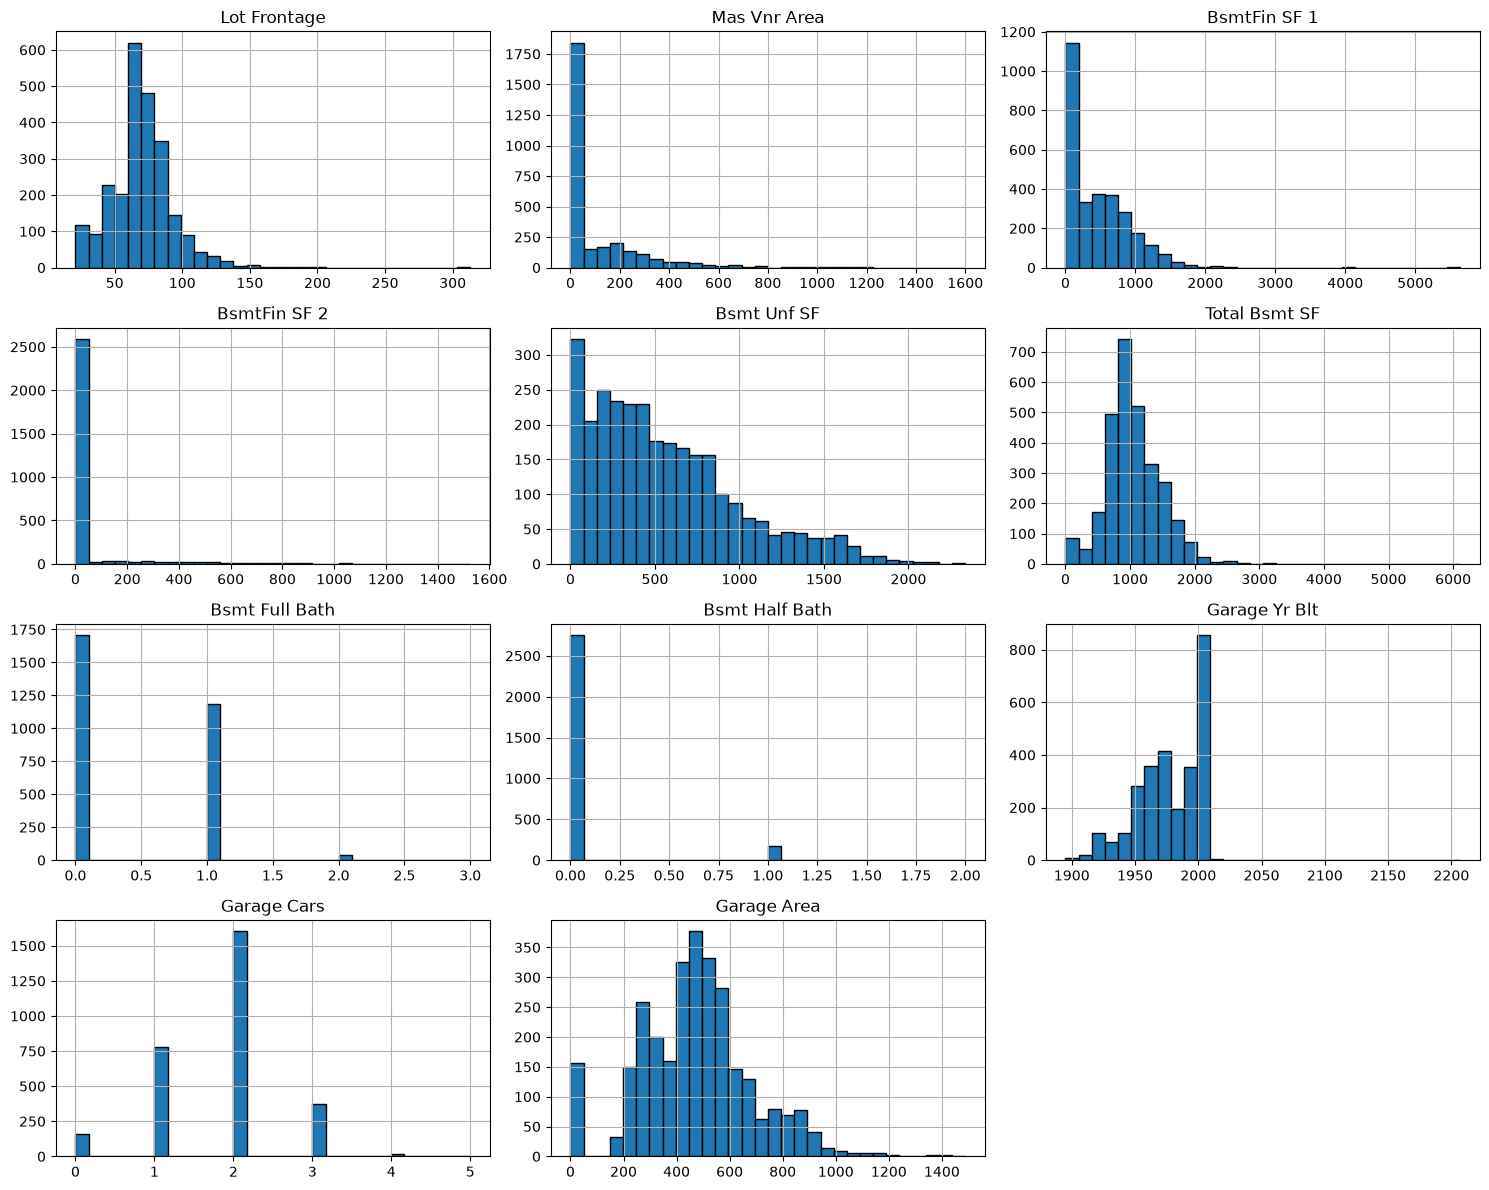

In [14]:
# plot histograms
df[num_cols_null].hist(figsize=(15, 12), bins=30, edgecolor='black')
plt.tight_layout()
plt.show()

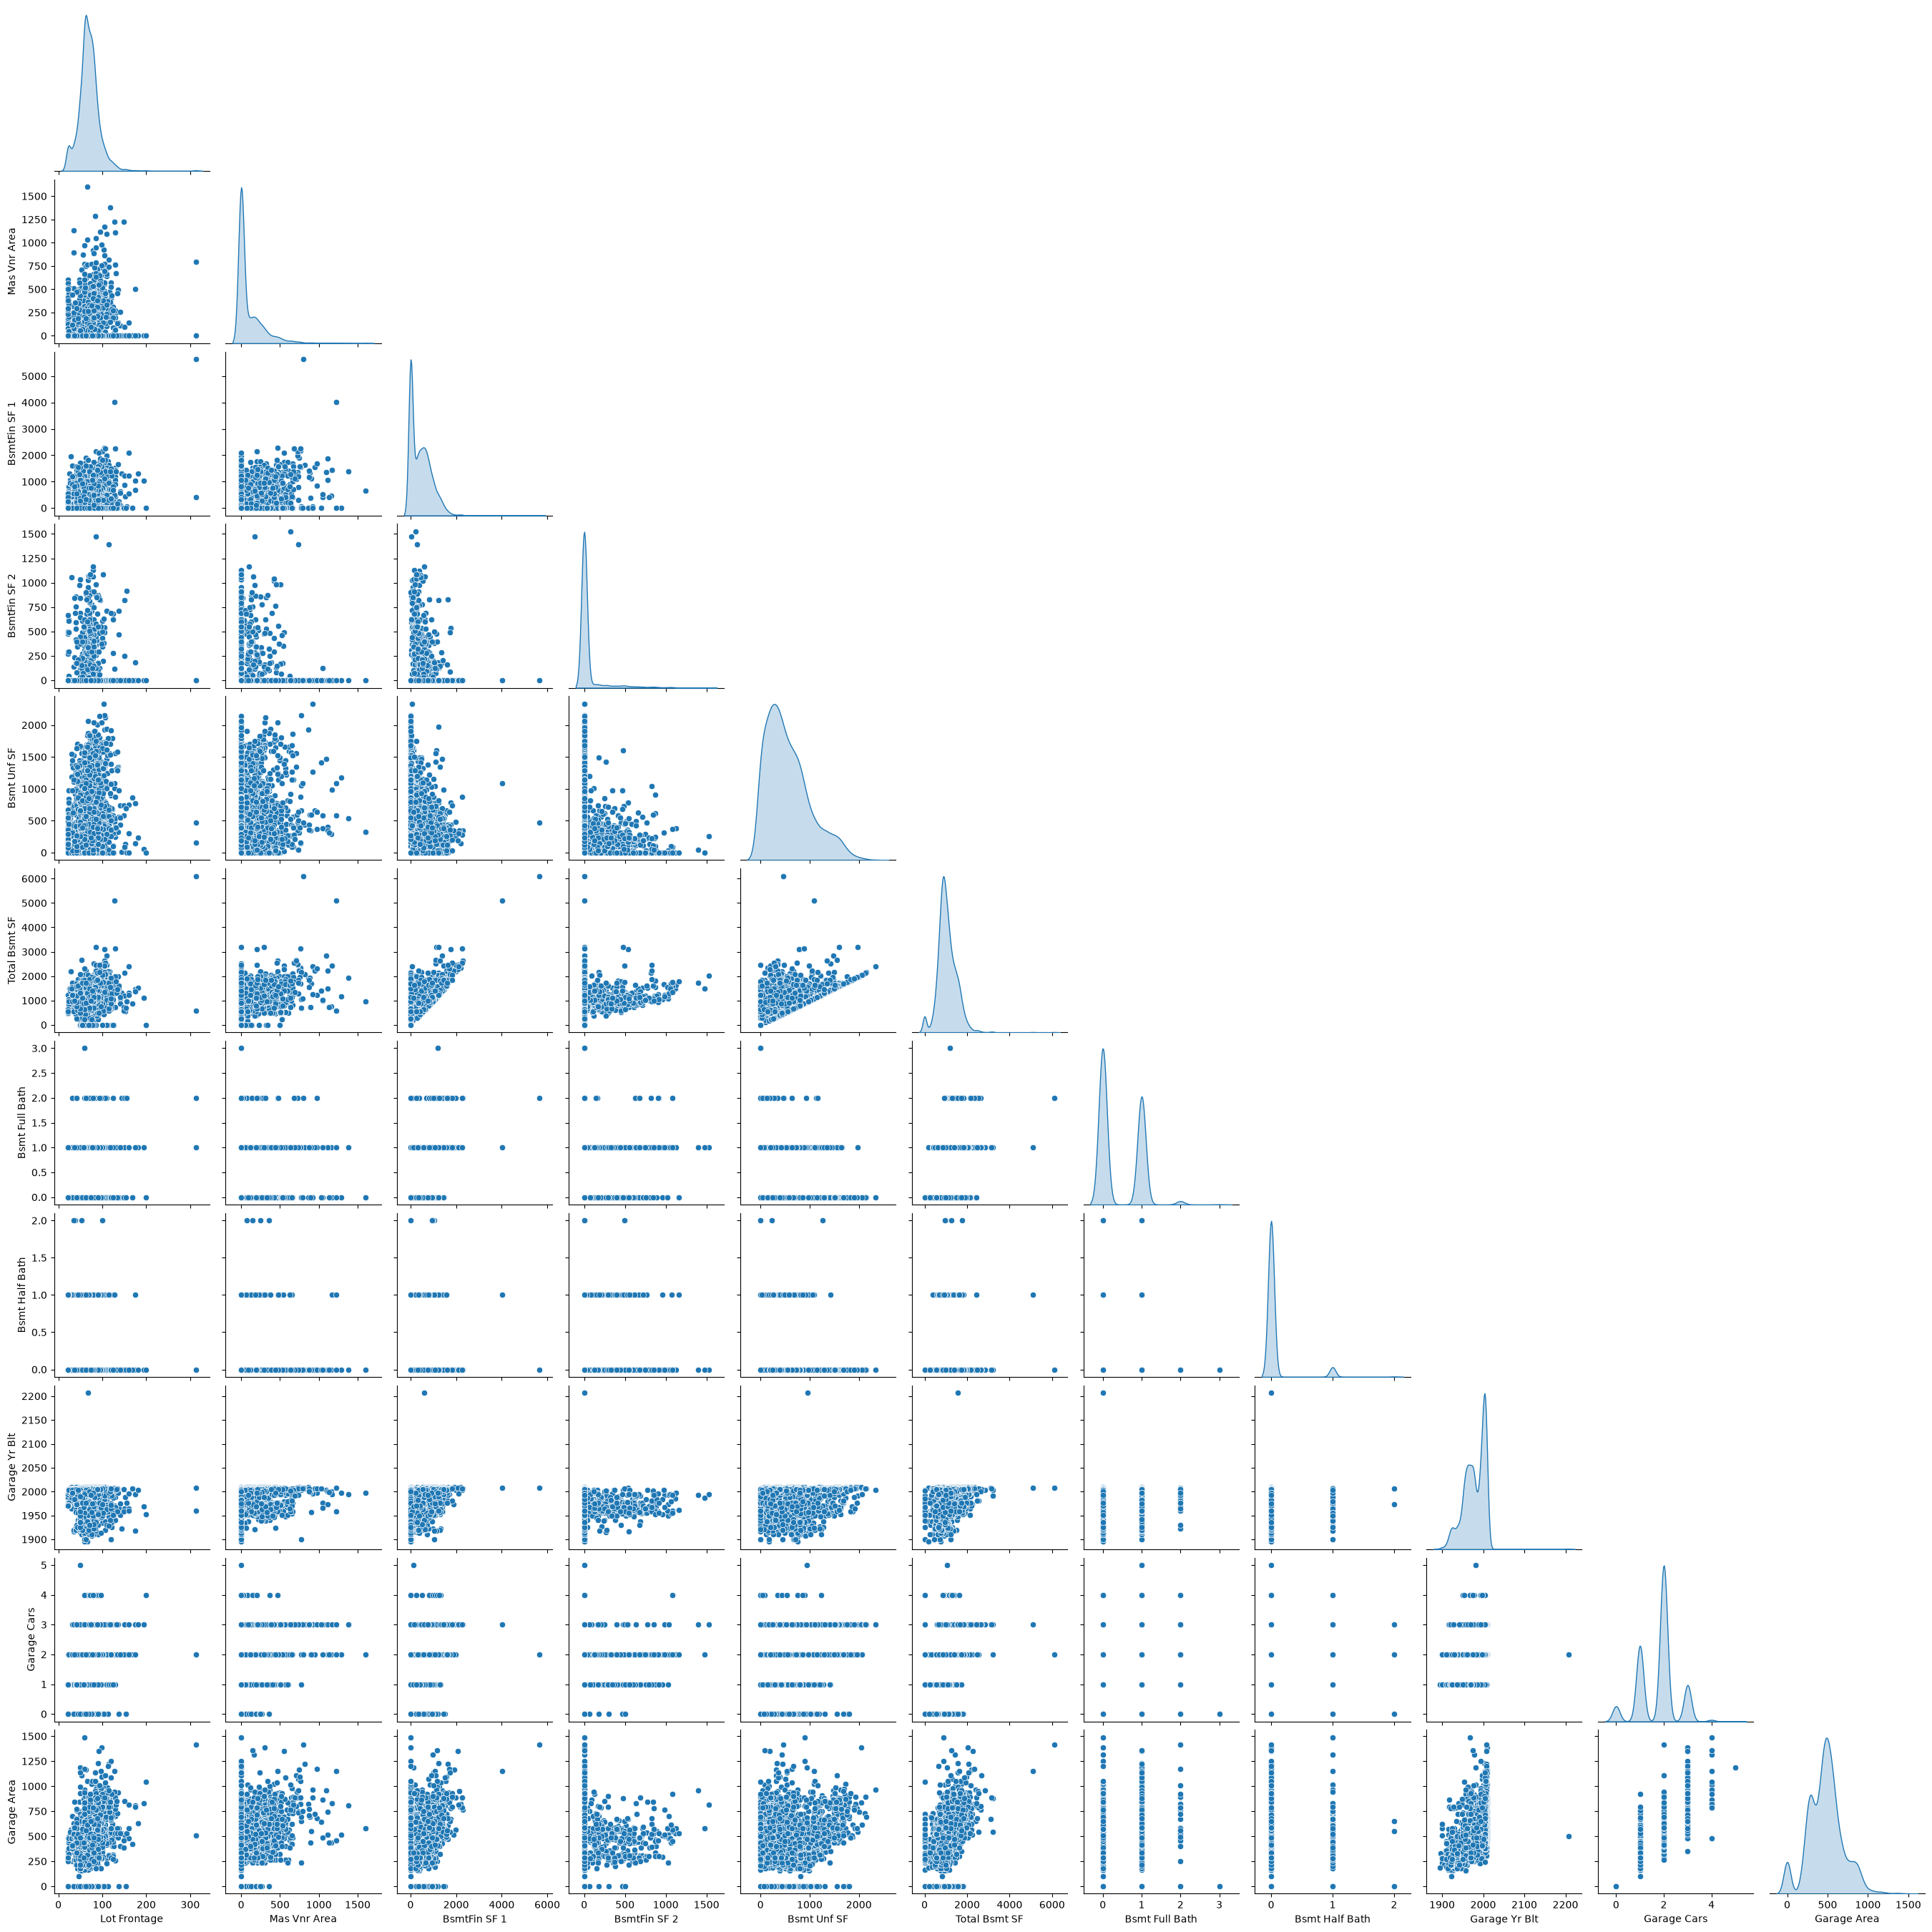

In [15]:
# Pair Plot (Scatterplot Matrix) with KDE Diagonals
sns.pairplot(df[num_cols_null], diag_kind='kde', corner=True)
plt.show()

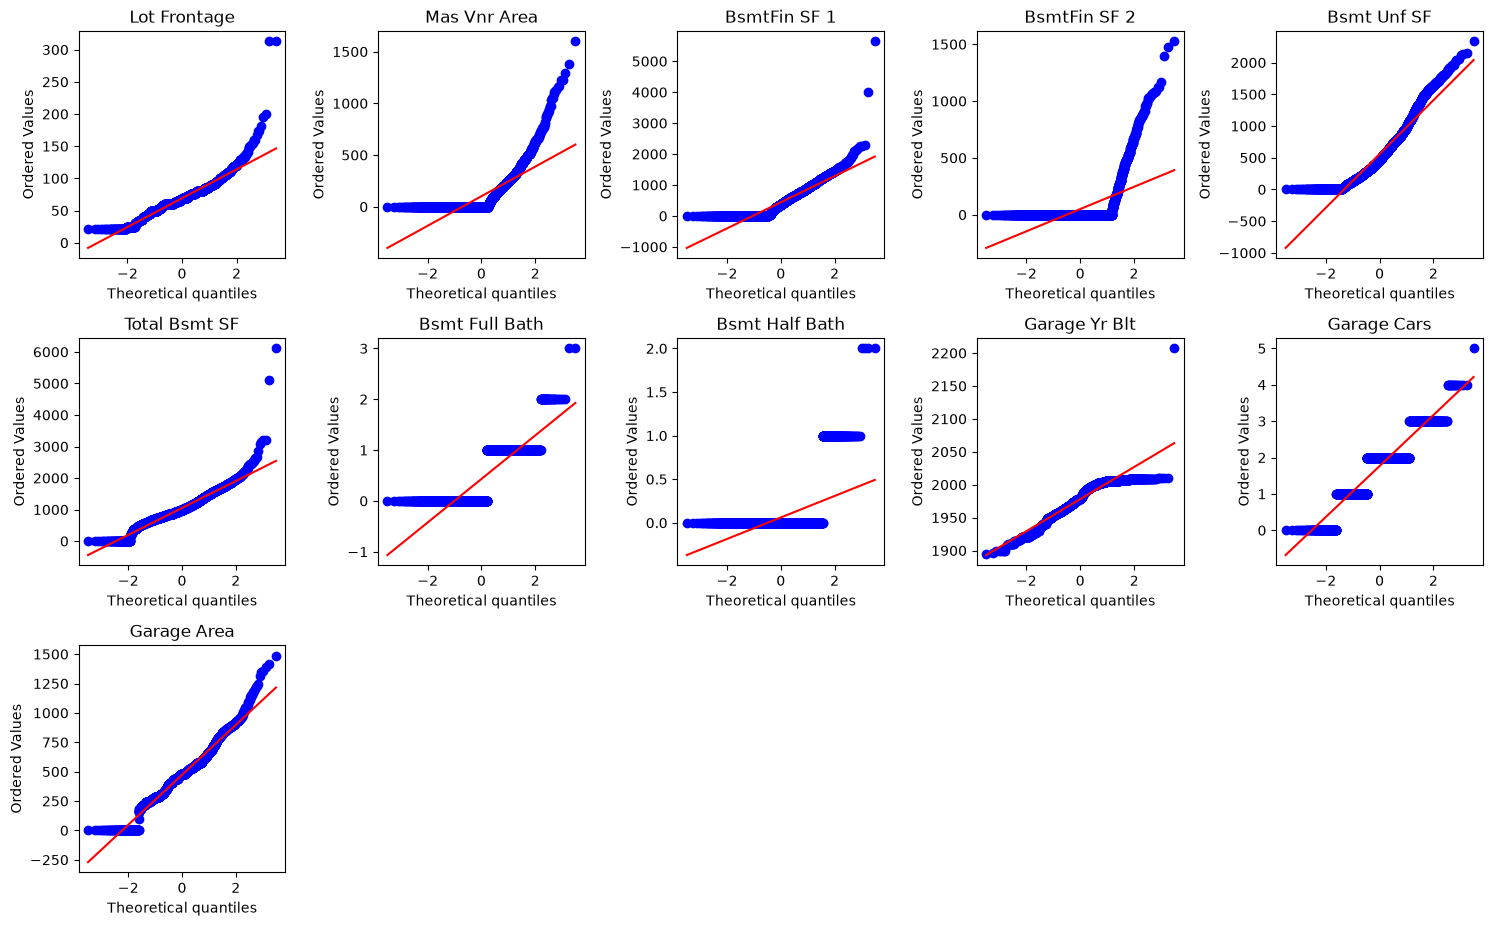

In [16]:
# Generate Q-Q plots for each numerical feature
plt.figure(figsize=(15, 12))
for i, column in enumerate(num_cols_null, 1):
    plt.subplot(4, 5, i)  # Adjust subplot layout as per number of features
    stats.probplot(df[column].dropna(), dist="norm", plot=plt)
    plt.title(column)

plt.tight_layout()
plt.show()

By using skewness we can detect where to apply mean and where to apply median

In [17]:
# check for skewed data
# Calculate skewness for each numerical column using skew and kurtosis
skewness = df[num_cols_null].apply(lambda x: skew(x.dropna()))

kurt = df[num_cols_null].apply(lambda x: kurtosis(x.dropna()))

# Combine skewness and kurtosis in a DataFrame
norm_null_df = pd.DataFrame({'Skewness': skewness, 'Kurtosis': kurt})
print(norm_null_df.sort_values(by = ['Skewness', 'Kurtosis'], ascending=[True, True]))

                Skewness   Kurtosis
Garage Yr Blt  -0.384463   1.821119
Garage Cars    -0.219724   0.242504
Garage Area     0.241870   0.947353
Bsmt Full Bath  0.616323  -0.748761
Bsmt Unf SF     0.922580   0.406779
Total Bsmt SF   1.155612   9.117977
BsmtFin SF 1    1.415457   6.845533
Lot Frontage    1.498146  11.209384
Mas Vnr Area    2.605639   9.268606
Bsmt Half Bath  3.938776  14.894223
BsmtFin SF 2    4.137858  18.747388


Handle missing values by inserting means and median according to its skewness or normality

In [18]:
# Optional KNN imputation for remaining missing numerical values
remaining_num_null = [c for c in num_cols_null if df[c].isnull().any()]

if remaining_num_null:
    knn_imputer = KNNImputer(n_neighbors=5, weights='distance')
    df[remaining_num_null] = knn_imputer.fit_transform(df[remaining_num_null])
    print(f"KNN-imputed numerical columns: {remaining_num_null}")
else:
    print("No remaining numerical nulls found for KNN imputation.")

print("Total remaining numerical nulls:", int(df.select_dtypes(include=['float64', 'int64']).isnull().sum().sum()))

KNN-imputed numerical columns: ['Lot Frontage', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Garage Yr Blt', 'Garage Cars', 'Garage Area']
Total remaining numerical nulls: 0


Fill missing data using mean and median depending on skewness.\
Note: Skewness between -0.5 and 0.5 = data is approximately symmetric\
Skewness between -1 and -0.5 = data is moderately skewed\
Skewness < -1 or Skewness > 1 = data is highly skewed

In [19]:
for row in norm_null_df.index:
    # for highly skewed.
    if norm_null_df.loc[row, "Skewness"] > 0.9 or norm_null_df.loc[row, "Skewness"] < -1:
        df[row] = df[row].fillna(df[row].median())
    else:
        df[row] = df[row].fillna(df[row].mean())

In [20]:
# Verify missing values after numerical imputation
remaining_missing = df.isnull().sum()
remaining_missing = remaining_missing[remaining_missing > 0].sort_values(ascending=False)

if remaining_missing.empty:
    print("No missing values remain in the dataset.")
else:
    print("Columns with remaining missing values:")
    print(remaining_missing)

Columns with remaining missing values:
Mas Vnr Type      1775
Fireplace Qu      1422
Garage Cond        159
Garage Qual        159
Garage Finish      159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Cond           80
Bsmt Qual           80
BsmtFin Type 1      80
Electrical           1
dtype: int64


## Deal with categorical features

In [21]:
# select all categorical columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
print(cat_cols)

# list of categorical features that contains null values
cat_cols_null = [cols for cols in lst_null_values if cols not in num_cols_null]
print(cat_cols_null)

['MS Zoning', 'Street', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC', 'Central Air', 'Electrical', 'Kitchen Qual', 'Functional', 'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond', 'Paved Drive', 'Sale Type', 'Sale Condition']
['Mas Vnr Type', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2', 'Electrical', 'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond']


C:\Users\A01411\AppData\Local\Temp\ipykernel_39000\2117959407.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()


Visualizing the Distribution of the Categorical Data

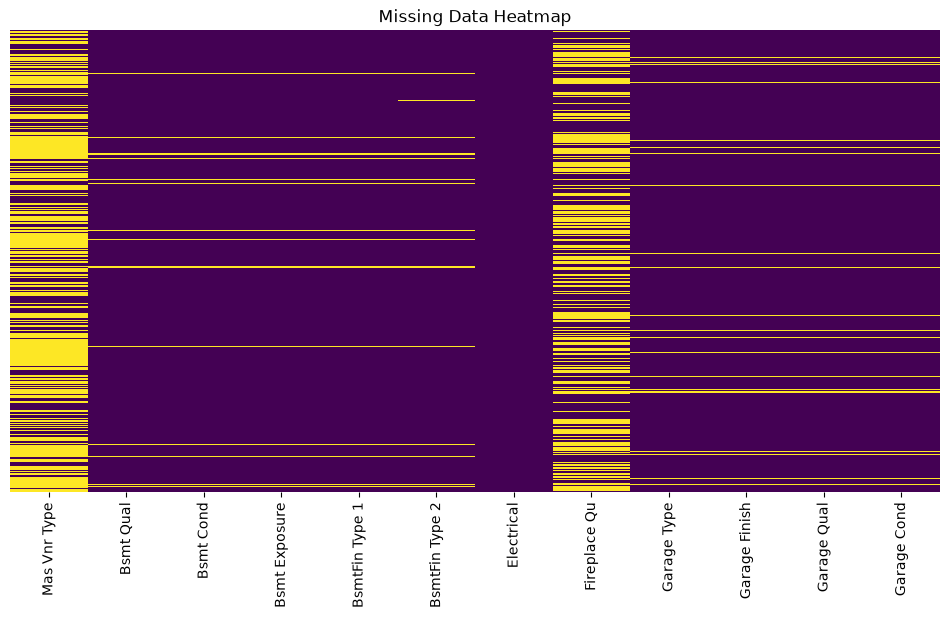

In [22]:
# Heatmap of missing data
# Heatmap helps us identify missingness patterns (random or systematic).

plt.figure(figsize=(12, 6))
sns.heatmap(df[cat_cols_null].isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Data Heatmap')
plt.show()

We can see here scattered missing values (random), simple imputation (mode or new category) might work here.
Output Interpretation:
Yellow indicate missing data.
Dark areas represent non-missing (available) data.

In the heat map, "Fireplace Qu" has much more missing values, and others have less missing values. On the other hand, "Mass Vnr Type" and "Electrical" has much less missing values <1%.

C:\Users\A01411\AppData\Local\Temp\ipykernel_39000\555930529.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=column, palette='Set2')
C:\Users\A01411\AppData\Local\Temp\ipykernel_39000\555930529.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=column, palette='Set2')
C:\Users\A01411\AppData\Local\Temp\ipykernel_39000\555930529.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=column, palette='Set2')
C:\Users\A01411\AppData\Local\Temp\ipykernel_39000\555930529.py:7: FutureWarning: 

Passing `pale

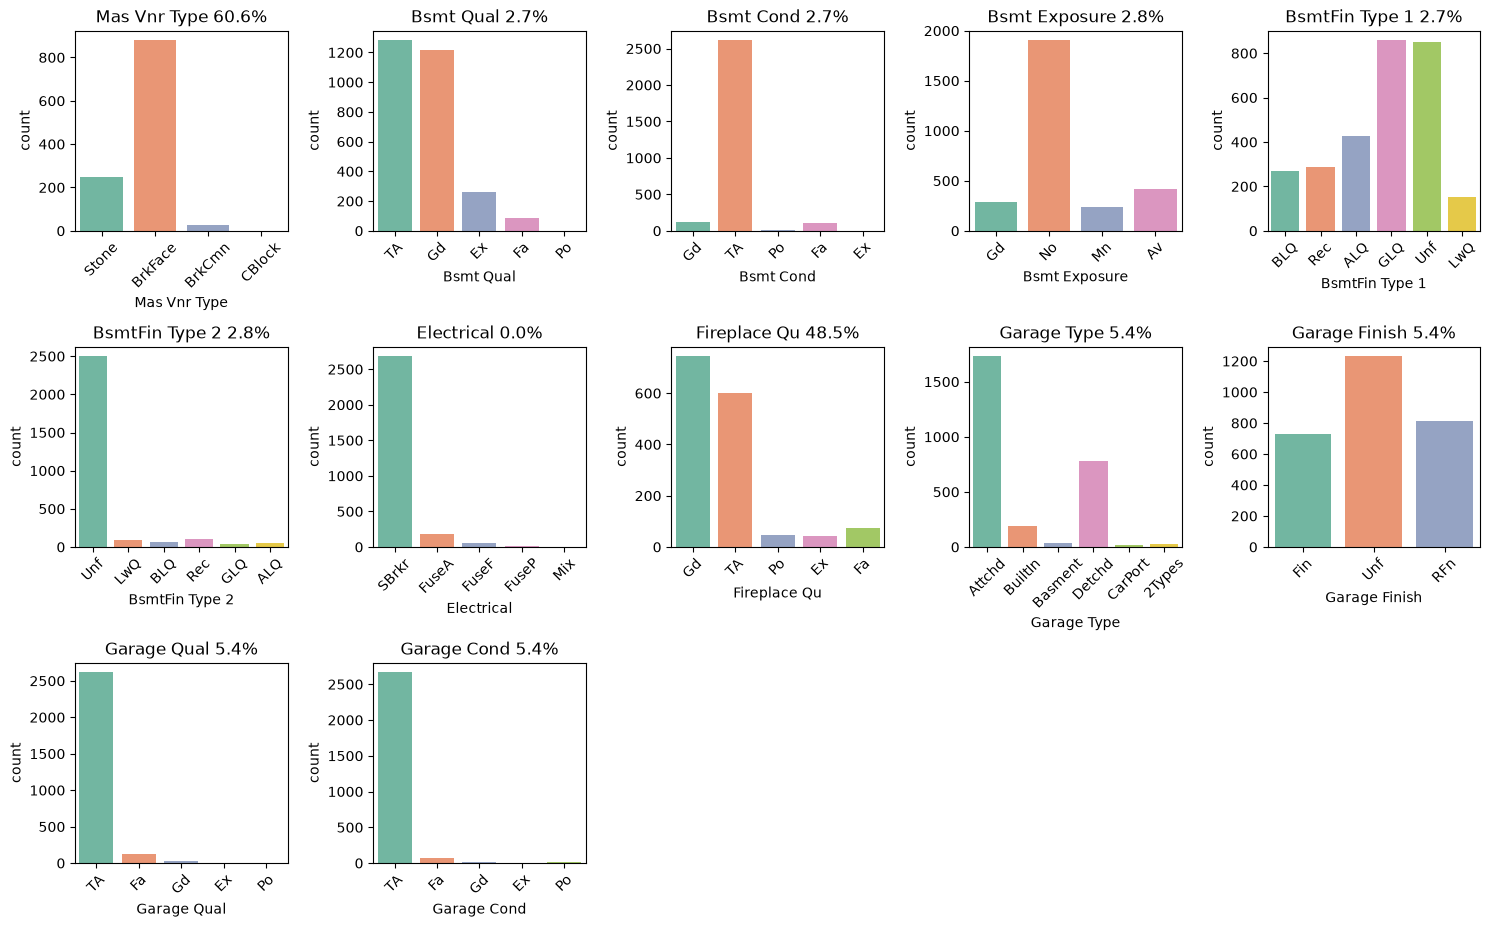

In [24]:
# Bar Plot, the distribution of a categorical variable
# Bar plots help assess if one category dominates (suitable for mode imputation) or if the data is more evenly spread (new category imputation may be better).

plt.figure(figsize=(15, 12))
for i, column in enumerate(cat_cols_null, 1):
    plt.subplot(4, 5, i)  # Adjust subplot layout as per number of features
    sns.countplot(data=df, x=column, palette='Set2')
    plt.title(column+ " "+f"{df[column].isnull().mean()*100:.1f}%") # print feature name along with the percantage of missing values in the feature
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In the above visualization, we can see that all the categorical features have much less missing values comparing their data except "Firplace Qu".\
Note: The percentage of missing values in each feature also influences the choice of imputation method. If the number of missing values is relatively small compared to the total number of records, mode imputation may be appropriate, especially if one of the dominant categories has a significantly higher frequency. Low percentage of missing values (e.g., <5-10%): Mode imputation is often safe because it wonâ€™t significantly distort the distribution. High percentage of missing values: In this case, creating a new category ("Unknown") ensures that the imputed values are clearly distinguishable from the real data, preventing potential bias.

According to the Bar plot, the following features we can use mode imputation-
1. Bsmt Cond
2. Bsmt Exposure
3. BsmtFin Type 2
4. Electrical
5. Garage Type
6. Garage Qual 
7. Garage Cond

Because, the plots show that one category dominates, thus mode imputation (most frequent) could make sense.

The following features then we can create an "Unknown" category-
1. Mas Vnr Type
2. Bsmt Qual
3. BsmtFin Type 1
4. Fireplace Qu
5. Garage Finish

In [25]:
# list of coulmns for Mode
mode = ['Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 2', 'Electrical', 'Garage Type', 'Garage Qual', 'Garage Cond']
# list of columns for New Category
new_category = ['Mas Vnr Type', 'Bsmt Qual', 'BsmtFin Type 1', 'Fireplace Qu', 'Garage Finish']

# Imputation with the Mode (Most Frequent Value)
for m in mode:
    most_frequent_value = df[m].mode()[0]
    # Impute missing values with the mode
    df[m] = df[m].fillna(most_frequent_value)

# Imputation with a New Category ("Unknown")
for c in new_category:
    df[c] = df[c].fillna('Unknown')

### Visualize the Impact of Imputation Methods
After trying different imputation methods, we can visualize the distribution of imputed values and compare them with the original (non-missing) values to see how well they match.

C:\Users\A01411\AppData\Local\Temp\ipykernel_39000\1491673907.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=column, palette='Set2')
C:\Users\A01411\AppData\Local\Temp\ipykernel_39000\1491673907.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=column, palette='Set2')
C:\Users\A01411\AppData\Local\Temp\ipykernel_39000\1491673907.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=column, palette='Set2')
C:\Users\A01411\AppData\Local\Temp\ipykernel_39000\1491673907.py:4: FutureWarning: 

Passing `

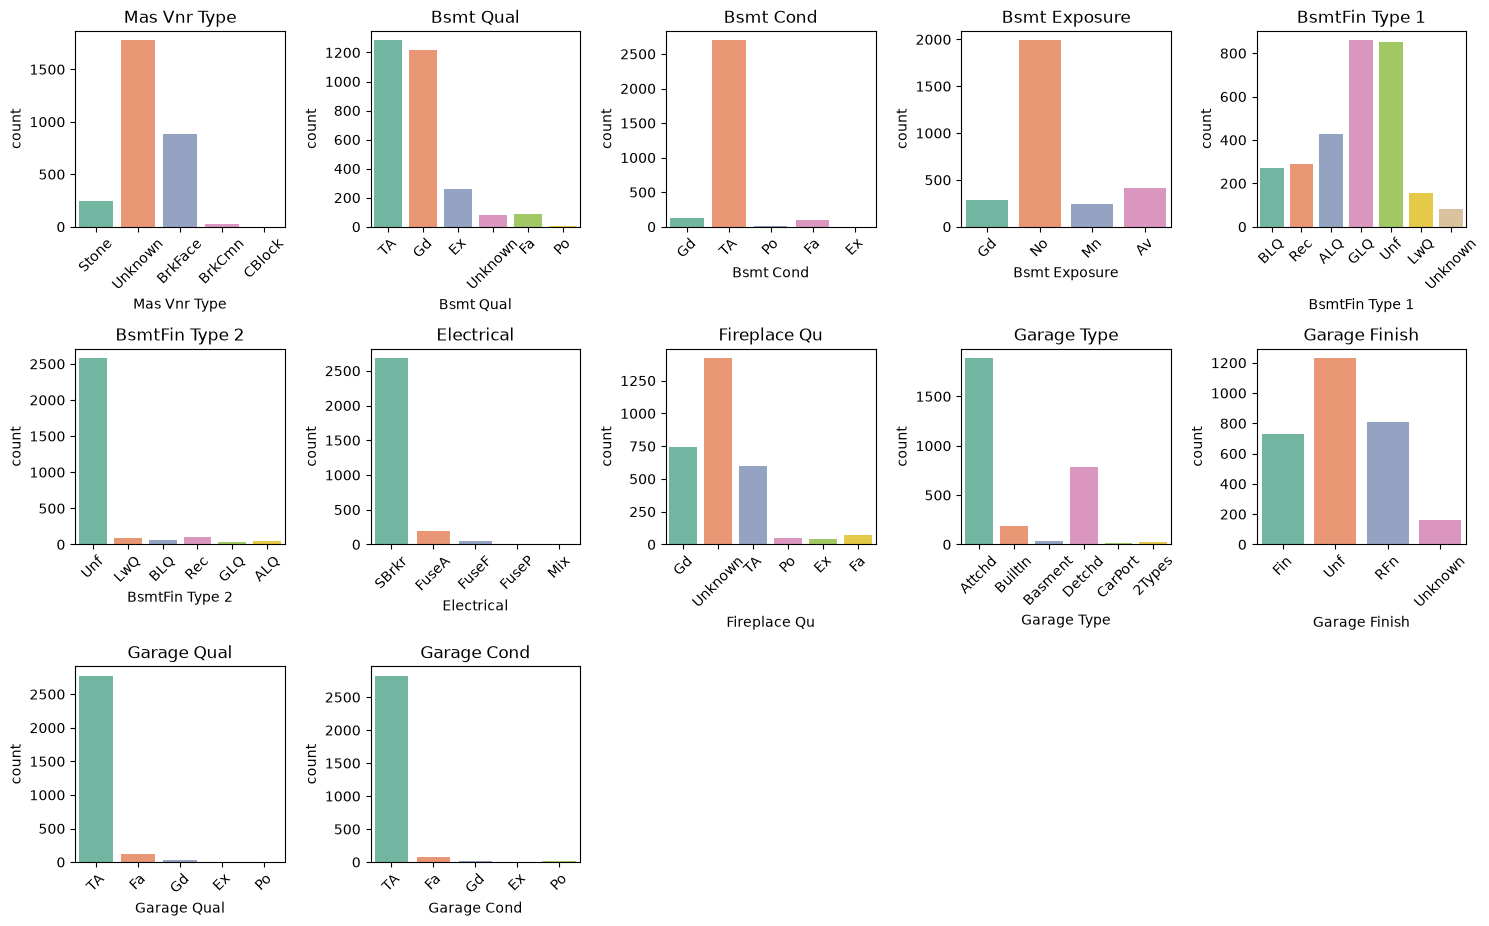

In [26]:
plt.figure(figsize=(15, 12))
for i, column in enumerate(cat_cols_null, 1):
    plt.subplot(4, 5, i)  # Adjust subplot layout as per number of features
    sns.countplot(data=df, x=column, palette='Set2')
    plt.title(column) # print feature name along with the percantage of missing values in the feature
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### for categorical features we will introduce more methods like correlation matrix for missing values, Use box plots or violin plots to compare how the missing and non-missing values affect other features (especially numerical ones). Then imputation using Machine Learning Models (like decision trees or k-nearest neighbors) also an advance approch

### Encode categorical variables.

We will use Multiple Encoding Techniques

When to Use which Method \
One-Hot Encoding: Use for nominal (unordered) categories and when the number of categories is small. Good for most algorithms.\
Label Encoding: Use for ordinal (ordered) categories or tree-based algorithms that can handle encoded values.\
Ordinal Encoding: Use for naturally ordered categories.\
Target Encoding: Use when you have high-cardinality features and want to capture the relationship between the categorical variable and the target.\
Frequency Encoding: Use when you have high-cardinality features and need to reduce dimensionality.\
Binary Encoding: Use for high-cardinality features as a memory-efficient alternative to one-hot encoding.

To determine the most appropriate encoding technique for categorical variables, we need to evaluate each variable based on three main factors:

1. Number of unique categories (to detect high cardinality).
2. Whether the variable is nominal or ordinal (to choose between ordinal or nominal encoding).
3. Distribution of categories (to decide between one-hot encoding, target encoding, etc.).

In [27]:
# define ordinal categories in a list (Manually)
ordinal_cat = ['Lot Shape', 'Land Slope', 'Exter Qual', 'Exter Cond', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1',
 'BsmtFin Type 2', 'Heating QC', 'Kitchen Qual', 'Fireplace Qu', 'Garage Qual', 'Garage Cond', 'Garage Finish', 'Functional', 'Paved Drive', 'Street', 'Central Air', 'Electrical', 'Utilities']

# Define the possible categories for each categorical feature
categories = [
    ['Reg', 'IR1', 'IR2', 'IR3'],                  # Lot Shape
    ['Gtl', 'Mod', 'Sev'],                         # Land Slope
    ['Ex', 'Gd', 'TA', 'Fa'],                      # Exter Qual
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],                # Exter Cond
    ['Ex', 'Gd', 'TA', 'Fa', 'Po', 'Unknown'],     # Bsmt Qual
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],                # Bsmt Cond
    ['Gd', 'Av', 'Mn', 'No'],                      # Bsmt Exposure
    ['GLQ', 'ALQ', 'BLQ', 'Rec', 'LwQ', 'Unf', 'Unknown'],  # BsmtFin Type 1
    ['GLQ', 'ALQ', 'BLQ', 'Rec', 'LwQ', 'Unf'],    # BsmtFin Type 2
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],                # Heating QC
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],                # Kitchen Qual
    ['Ex', 'Gd', 'TA', 'Fa', 'Po', 'Unknown'],     # Fireplace Qu
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],                # Garage Qual
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],                # Garage Cond
    ['Fin', 'RFn', 'Unf', 'Unknown'],              # Garage Finish
    ['Typ', 'Min1', 'Min2', 'Mod', 'Maj1', 'Maj2', 'Sev', 'Sal'],  # Functional
    ['Y', 'P', 'N'],                               # Paved Drive
    ['Pave', 'Grvl'],                              # Street
    ['Y', 'N'],                                    # Central Air
    ['SBrkr', 'FuseA', 'FuseF', 'FuseP', 'Mix'],   # Electrical
    ['AllPub', 'NoSewr', 'NoSeWa']                 # Utilities
]

In [28]:
# a function that seperate high cardinality, nominal and ordinal variables in the datasets
def check_category_type(df, threshold=10):
    variable_info = {}
    nominal_cat = [] # define nominal categories in a list
    hc_cat = [] # define high cardinality categories in a list
    
    for col in cat_cols:
        unique_values = df[col].nunique()
        is_ordinal = col in ordinal_cat
        
        # Decide on encoding based on number of unique values and type
        if unique_values > threshold:
            encoding = 'High cardinality'
            hc_cat.append(col)
        elif is_ordinal:
            encoding = 'Ordinal'
        else:
            encoding = 'Nominal'
            nominal_cat.append(col)
        
        variable_info[col] = {
            'Unique Categories': unique_values,
            'Category Type': encoding
        }
    
    return pd.DataFrame(variable_info).T, nominal_cat, hc_cat

In [29]:
variable_analysis, nominal_cat, hc_cat = check_category_type(df)
print(variable_analysis)

               Unique Categories     Category Type
MS Zoning                      7           Nominal
Street                         2           Ordinal
Lot Shape                      4           Ordinal
Land Contour                   4           Nominal
Utilities                      3           Ordinal
Lot Config                     5           Nominal
Land Slope                     3           Ordinal
Neighborhood                  28  High cardinality
Condition 1                    9           Nominal
Condition 2                    8           Nominal
Bldg Type                      5           Nominal
Roof Style                     6           Nominal
Roof Matl                      8           Nominal
Exterior 1st                  16  High cardinality
Exterior 2nd                  17  High cardinality
Mas Vnr Type                   5           Nominal
Exter Qual                     4           Ordinal
Exter Cond                     5           Ordinal
Foundation                     

We will use\
One-Hot Encoding for Nominal variables,\
Ordinal Encoding for Ordinal variables,\
Binary Encoding for High cardinality variables.

### Dealing with outliers

Visualization using Boxplot and Histogram



In [30]:
# Plotting histograms and boxplots
# Calculate the figure layout based on the number of columns
def Visualize_box_hist(df, n_cols, n_rows, num_clos):

    fig, axes = plt.subplots(n_rows, 2, figsize=(14, 4 * n_rows))

    # Loop through each numerical column and plot both histogram and boxplot
    for i, column in enumerate(num_clos):
        # Plot histogram on the left
        sns.histplot(df[column], bins=30, color='skyblue', ax=axes[i, 0])
        axes[i, 0].set_title(f'Histogram of {column}')

        # Plot boxplot on the right
        sns.boxplot(y=df[column], ax=axes[i, 1])
        axes[i, 1].set_title(f'Box Plot of {column}')

    # Adjust layout for better readability
    plt.tight_layout()
    plt.show()

n_cols = 2  # Number of columns per row
n_rows = len(num_clos)  # Calculate required rows
Visualize_box_hist(df, n_cols, n_rows, num_clos)

In the above Visualization we can decide as follows:

Histogram Analysis: 
If the histogram shows a strong right skew (a long tail toward higher values):
Log Transformation is likely a good choice, as it can reduce skewness by compressing higher values.
If the histogram appears nearly symmetric with a few extreme values on the right:
Capping may be more suitable, as it can control the impact of these extreme values without altering the overall distribution.

Box Plot Analysis:
If the box plot shows many points beyond the upper whisker, indicating frequent outliers:
Log Transformation may help if these are high-value outliers, as it can scale them down and reduce their influence.
If the box plot has only a few points as outliers but they are significantly distant from the box:
Capping might be sufficient to handle these isolated high values without altering the overall shape of the data.

Statistiacl Methods to measure outliers

In [31]:
# Dictionary to store the count of outliers for each column
outliers_count = {}
outliers_count_after = {}

# we need these list for later dealing outliers in pipeline
remove_outliers = []
cap_outliers = []
#transform_outliers = []

for cols in num_clos:
    Q1 = df[cols].quantile(0.25)
    Q3 = df[cols].quantile(0.75)
    IQR = Q3 - Q1
    
    # Define lower and upper bounds for outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = int(df[(df[cols] < lower_bound) | (df[cols] > upper_bound)].shape[0])
    outliers_count[cols] = {'Num of Outliers': outliers}
    
    if cols == "Year Built": # Year Built is our target feature. Keep labels intact: no removal, capping or transformation.
        pass
    else:
        # no outliers so nothing to do here
        if outliers == 0:
            pass
        # here we remove outliers
        elif outliers > 0 and outliers < 21:
            remove_outliers.append(cols)
            # Remove rows where a certain feature is outside bounds
            df = df[(df[cols] >= lower_bound) & (df[cols] <= upper_bound)]
            
        # here we cap outliers
        #elif outliers >= 21 and outliers < 200:
        #    cap_outliers.append(cols)
        #    # Cap values outside the bounds
        #    df[cols] = np.where(df[cols] < lower_bound, lower_bound, df[cols])
        #    df[cols] = np.where(df[cols] > upper_bound, upper_bound, df[cols])

        # here we cap outliers
        else:
            cap_outliers.append(cols)
            df[cols] = np.where(df[cols] < lower_bound, lower_bound, df[cols])
            df[cols] = np.where(df[cols] > upper_bound, upper_bound, df[cols])
            
            
    # Re-evaluate IQR for Consistency
    outliers_after = df[(df[cols] < lower_bound) | (df[cols] > upper_bound)]
    outliers_count_after[cols] = {'Num of Outliers after': outliers_after.shape[0]}

print(pd.DataFrame(outliers_count).T)
print(remove_outliers)
print(cap_outliers)
#print(transform_outliers)

print(pd.DataFrame(outliers_count_after).T)


                      Num of Outliers
Order                               0
PID                                 0
MS SubClass                       208
Lot Frontage                      201
Lot Area                          127
Overall Qual                        4
Overall Cond                      249
Year Built                          9
Mas Vnr Area                      201
BsmtFin SF 1                       14
BsmtFin SF 2                      351
Bsmt Unf SF                        53
Total Bsmt SF                     107
1st Flr SF                         30
2nd Flr SF                          7
Low Qual Fin SF                    40
Gr Liv Area                        68
Bsmt Full Bath                      2
Bsmt Half Bath                    173
Full Bath                           4
Half Bath                           0
Bedroom AbvGr                      72
Kitchen AbvGr                     129
TotRms AbvGrd                      47
Fireplaces                         12
Garage Yr Bl

In above, we Show first number of outliers for each features.\
For Features with a Very High Count of Outliers (â‰¥ 200): we use Transformation method. \
For Features with Moderate Outlier Counts (21 - 199): we use Cap the Outliers method.\
For Features with Low to Moderate Outlier Counts (1 - 20): we use Remove Outliers.

Check some methods wheather outliers are dealt effectively:
1. Visualization
2. Check Skewness and Kurtosis



In [32]:
n_cols = 2  # Number of columns per row
n_rows = len(num_clos)  # Calculate required rows
Visualize_box_hist(df, n_cols, n_rows, num_clos)

In [33]:
# Check Skewness and Kurtosis
skew_kurt = {}
for column in num_clos:
    skewness = df[column].skew()
    kurtosis = df[column].kurtosis()
    skew_kurt[column] = {'Skewness': skewness, 'Kurtosis': kurtosis}
    print(f"{column} - Skewness: {skewness}, Kurtosis: {kurtosis}")

Order - Skewness: 0.0012126958038579392, Kurtosis: -1.1957868685089228
PID - Skewness: 0.057131906987150635, Kurtosis: -1.995056047517875
MS SubClass - Skewness: 0.9882128106592531, Kurtosis: 0.0722065114687016
Lot Frontage - Skewness: 0.07155209948490653, Kurtosis: -0.015075788375761512
Lot Area - Skewness: 0.18820169870408437, Kurtosis: 0.10715962685755942
Overall Qual - Skewness: 0.20834893283435604, Kurtosis: -0.1314875294982767
Overall Cond - Skewness: 0.5881623435326949, Kurtosis: -0.3498415574898672
Year Built - Skewness: -0.5920109447388412, Kurtosis: -0.5317907230540073
Mas Vnr Area - Skewness: 1.322672033490532, Kurtosis: 0.4056060368634893
BsmtFin SF 1 - Skewness: 0.7361124383284791, Kurtosis: -0.30956588589151757
BsmtFin SF 2 - Skewness: 0.0, Kurtosis: 0.0
Bsmt Unf SF - Skewness: 0.8234557865328482, Kurtosis: 0.010257210997679067
Total Bsmt SF - Skewness: 0.1803831202592204, Kurtosis: 0.203211459106162
1st Flr SF - Skewness: 0.6170533027820723, Kurtosis: -0.1384142674199675

Features Where Outliers Are Managed Well:

Order, PID, Lot Frontage, Lot Area, Total Bsmt SF, SalePrice: These features have skewness values close to zero, indicating a near-symmetric distribution, which should work well for linear modeling. Outliers appear to be effectively managed here, resulting in balanced distributions.

Bedroom AbvGr, Gr Liv Area, Garage Area, Mo Sold, Yr Sold: These features also show minimal skewness and kurtosis close to zero, suggesting that they are now well-distributed and unlikely to introduce bias or instability in model training.

Features with Acceptable Results but Minor Skew or Kurtosis:

Right-Skewed Features:\
Mas Vnr Area, Wood Deck SF, Open Porch SF: These features still have moderate right skew, which may cause slight asymmetry. Further transformations (log or square root) could reduce the skew if necessary, though current distributions are likely manageable in most models.

Left-Skewed Features:\
Year Built, Year Remod/Add, Garage Yr Blt: These show moderate left skew, common for features bounded by date or time scales. They are acceptable for modeling as is but could be transformed if further symmetry is desired.

Platykurtic (Flatter) Features:\
Order, PID, Overall Cond, Year Built, Year Remod/Add: These features have flatter, broader distributions than normal, likely reducing extreme outliers' influence. Their current distributions should be sufficient, though the broader spread may warrant further review if model sensitivity arises.

Features Needing Further Attention:

Highly Skewed Features:\
Wood Deck SF, Open Porch SF: Although skewness was reduced, their right-skewed distribution may still need transformation if affecting model results.

Low-Variance Features:\
BsmtFin SF 2, Bsmt Half Bath, Kitchen AbvGr, Misc Val: These have zero kurtosis, indicating either binary or low-variance data. Their low variance may affect some models and could benefit from encoding adjustments or re-evaluation.

Leptokurtic (Peaked) Features:\
SalePrice, Garage Area, Mas Vnr Area: These show slight positive kurtosis, making them more peaked around the mean. This could lead to minor concentration around a central value, which might benefit from normalization or transformation if variability is needed for the modelâ€™s purpose.

In [34]:
zero_skew_kurt = [k for k, v in skew_kurt.items() if v["Skewness"] == 0 and v["Kurtosis"] == 0]
variance = df[zero_skew_kurt].var()
variance

BsmtFin SF 2       0.0
Low Qual Fin SF    0.0
Bsmt Half Bath     0.0
Kitchen AbvGr      0.0
Enclosed Porch     0.0
3Ssn Porch         0.0
Screen Porch       0.0
Pool Area          0.0
Misc Val           0.0
dtype: float64

These features with 0 Skewness and 0 Kurtosis have the variance 0. That means, the feature does not change across observations; every row has the same value for that feature.

Impact on Machine Learning Models:\
No Predictive Power: Features with zero variance do not provide any information to help differentiate observations, so they add no value to predictive modeling.
Potential Model Issues: Some algorithms (like linear regression or logistic regression) might have trouble with zero-variance features, as they can lead to singular matrices or redundant calculations.

Recommended Actions:\
Drop the Feature: As the variance is zero, generally dropping the feature from the dataset is good idea, as it provides no information that can aid in model training or improve performance.

In [35]:
# dropping all features those variance is 0
df.drop(columns=zero_skew_kurt, inplace=True)

In [36]:
# after dropping features we calculate again here the total number of numerical features
# select all numerical columns
num_clos = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

### Transformation

When a feature is skewed, especially if itâ€™s highly skewed, it can lead to poor model performance. Applying transformations to these skewed features helps make their distributions closer to normal, which can improve the accuracy and stability of your models.

Types of Skewness:\
Right (Positive) Skew: Data with a long tail on the right side (e.g., income, house prices).
Left (Negative) Skew: Data with a long tail on the left side (e.g., scores where most people perform well).

steps:
1. Calculate skewness (Which is already calculated after dealing outliers)
2. Perform transformation:\
Apply a log transformation for Highly positive skew (>=1)\
Apply Yeo-Johnson Transformation Slight Negative Skewness (<-0.5)\
Apply a square root for moderate positive skewness (between 0.5 to 1)\
Do nothing (-0.5 to 0.5)

For most cases, a skewness value > 0.5 or < -0.5 is considered skewed and might benefit from transformation.

Target feature "Year Built" is the construction year we want to predict, so we keep it in its original calendar-year scale and do not apply any transformation to it.


In [37]:
for col in num_clos:
    print(f"{col} contains any negative values: {(df[col]<0).any()}")        

Order contains any negative values: False
PID contains any negative values: False
MS SubClass contains any negative values: False
Lot Frontage contains any negative values: False
Lot Area contains any negative values: False
Overall Qual contains any negative values: False
Overall Cond contains any negative values: False
Year Built contains any negative values: False
Mas Vnr Area contains any negative values: False
BsmtFin SF 1 contains any negative values: False
Bsmt Unf SF contains any negative values: False
Total Bsmt SF contains any negative values: False
1st Flr SF contains any negative values: False
2nd Flr SF contains any negative values: False
Gr Liv Area contains any negative values: False
Bsmt Full Bath contains any negative values: False
Full Bath contains any negative values: False
Half Bath contains any negative values: False
Bedroom AbvGr contains any negative values: False
TotRms AbvGrd contains any negative values: False
Fireplaces contains any negative values: False
Gar

Above we check that all features contains no negative values. So we can safely use log transformation, even Box-Cox.

In [ ]:
# Clean any inf/-inf values that might exist from previous steps
df_numeric = df.select_dtypes(include=[np.number])
for col in df_numeric.columns:
    df[col] = df[col].replace([np.inf, -np.inf], np.nan)
    if df[col].isna().any():
        df[col].fillna(df[col].median(), inplace=True)

# Apply transformations to reduce skewness for better model performance
# Store column names in lists for reference in the pipeline
log_transform = []
square_transform = []
yeo_johnson_transform = []

for k in skew_kurt.keys():
    # never transform the target ("Year Built") so labels stay in real calendar years
    if k == "Year Built":
        continue
    if skew_kurt[k]["Skewness"] != 0:
        # do nothing (skewness between -0.5 and 0.5 is approximately symmetric)
        if skew_kurt[k]["Skewness"] < 0.5 and skew_kurt[k]["Skewness"] > -0.5:
            pass
        # log transformation (highly right-skewed: skewness >= 1)
        elif skew_kurt[k]["Skewness"] >= 1:
            log_transform.append(k)
            df[k] = np.log1p(df[k])
        # square root transformation (moderate right-skew: 0.5 <= skewness < 1)
        elif skew_kurt[k]["Skewness"] >= 0.5 and skew_kurt[k]["Skewness"] < 1:
            square_transform.append(k)
            df[k] = np.sqrt(df[k])
        # yeo johnson transformation (slight negative skew or other cases)
        else:
            yeo_johnson_transform.append(k)
            pt = PowerTransformer(method='yeo-johnson')
            transformed = pt.fit_transform(df[[k]]).flatten()
            # Replace any inf/-inf values with NaN, then fill with median
            transformed = np.where(np.isinf(transformed), np.nan, transformed)
            df[k] = pd.Series(transformed, index=df.index).fillna(df[k].median())

print(f"Columns for log transformation: {log_transform}")
print(f"Columns for square-root transformation: {square_transform}")
print(f"Columns for Yeo-Johnson transformation: {yeo_johnson_transform}")

ValueError: Input X contains infinity or a value too large for dtype('float64').

log_transform : log transformation,\
square_transform: Square Root transformation,\
yeo_johnson_transform: Yeo-Johnson Transformation. 

These 3 lists contains feature names that need to be performed certain transformation. We will use these lists when performing transformation in pipeline.

In [45]:
# Check Skewness and Kurtosis
skew_kurt = {}
for column in num_clos:
    skewness = df[column].skew()
    kurtosis = df[column].kurtosis()
    skew_kurt[column] = {'Skewness': skewness, 'Kurtosis': kurtosis}
    print(f"{column} - Skewness: {skewness}, Kurtosis: {kurtosis}")

Order - Skewness: 0.0012126958038579392, Kurtosis: -1.1957868685089228
PID - Skewness: 0.057131906987150635, Kurtosis: -1.995056047517875
MS SubClass - Skewness: 0.31356228340369824, Kurtosis: -1.1032010653220743
Lot Frontage - Skewness: 0.07155209948490653, Kurtosis: -0.015075788375761512
Lot Area - Skewness: 0.18820169870408437, Kurtosis: 0.10715962685755942
Overall Qual - Skewness: 0.20834893283435604, Kurtosis: -0.1314875294982767
Overall Cond - Skewness: 0.4000180668218925, Kurtosis: -0.25816949739534767
Year Built - Skewness: -0.5920109447388412, Kurtosis: -0.5317907230540073
Mas Vnr Area - Skewness: 0.4451496740657935, Kurtosis: -1.770401759047837
BsmtFin SF 1 - Skewness: -0.07409379216262918, Kurtosis: -1.417691720430047
Bsmt Unf SF - Skewness: -0.27288123239899686, Kurtosis: -0.3316942760154298
Total Bsmt SF - Skewness: 0.1803831202592204, Kurtosis: 0.203211459106162
1st Flr SF - Skewness: 0.27900611770915285, Kurtosis: -0.41669072169129917
2nd Flr SF - Skewness: 0.43878590559

c:\Users\A01411\OneDrive - Uniper IT GmbH\Documents\University documents\Statistical Learning\ames-housing-analysis\.venv\Lib\site-packages\pandas\core\nanops.py:1275: RuntimeWarning: invalid value encountered in subtract
  adjusted = values - mean
c:\Users\A01411\OneDrive - Uniper IT GmbH\Documents\University documents\Statistical Learning\ames-housing-analysis\.venv\Lib\site-packages\pandas\core\nanops.py:1364: RuntimeWarning: invalid value encountered in subtract
  adjusted = values - mean


### Feature Scaling (Normalization or Standardization) for numerical features

First we visualize wheather all features are normally distributed. If they are normally distributed, then we perform Standardization otherwise we will perform Normalization.

Standardize features close to normal distributions. Skewness is close to 0 (between -0.5 and 0.5), and kurtosis is also within a reasonable range (typically between -1 and +1)

Normalize features with higher skewness and kurtosis extremes. Features with higher skewness (|skewness| > 0.5) and/or more extreme kurtosis values (kurtosis less than -1.5 or greater than 1.5)

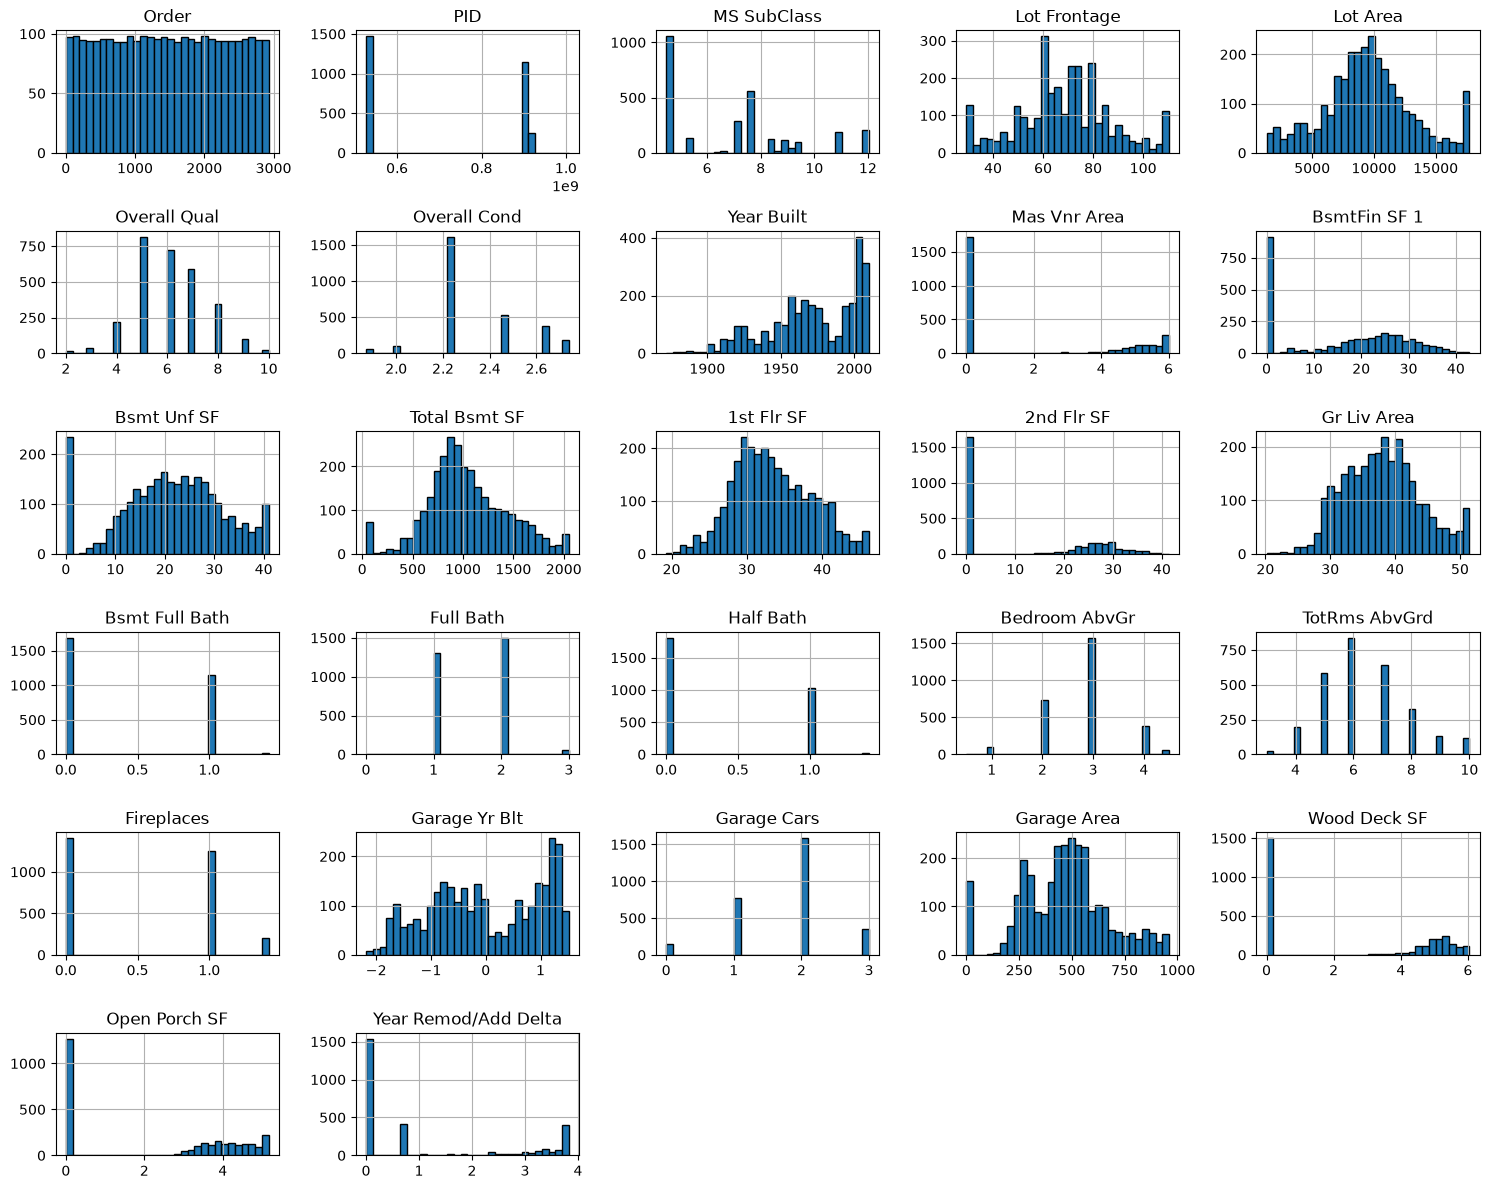

In [41]:
# plot histograms (filter out infinite values that may result from transformations)
df_plot = df[num_clos].replace([np.inf, -np.inf], np.nan)
df_plot.hist(figsize=(15, 12), bins=30, edgecolor='black')
plt.tight_layout()
plt.show()

In [42]:
# Check Skewness and Kurtosis
for column in num_clos:
    skewness = df[column].skew()
    kurtosis = df[column].kurtosis()
    print(f"{column} - Skewness: {skewness}, Kurtosis: {kurtosis}")

Order - Skewness: 0.0012126958038579392, Kurtosis: -1.1957868685089228
PID - Skewness: 0.057131906987150635, Kurtosis: -1.995056047517875
MS SubClass - Skewness: 0.524451079163444, Kurtosis: -0.7896341401597455
Lot Frontage - Skewness: 0.07155209948490653, Kurtosis: -0.015075788375761512
Lot Area - Skewness: 0.18820169870408437, Kurtosis: 0.10715962685755942
Overall Qual - Skewness: 0.20834893283435604, Kurtosis: -0.1314875294982767
Overall Cond - Skewness: 0.4000180668218925, Kurtosis: -0.25816949739534767
Year Built - Skewness: -0.5920109447388412, Kurtosis: -0.5317907230540073
Mas Vnr Area - Skewness: 0.5085436604426593, Kurtosis: -1.6499247179427252
BsmtFin SF 1 - Skewness: -0.07409379216262918, Kurtosis: -1.417691720430047
Bsmt Unf SF - Skewness: -0.27288123239899686, Kurtosis: -0.3316942760154298
Total Bsmt SF - Skewness: 0.1803831202592204, Kurtosis: 0.203211459106162
1st Flr SF - Skewness: 0.27900611770915285, Kurtosis: -0.41669072169129917
2nd Flr SF - Skewness: 0.438785905590

c:\Users\A01411\OneDrive - Uniper IT GmbH\Documents\University documents\Statistical Learning\ames-housing-analysis\.venv\Lib\site-packages\pandas\core\nanops.py:1275: RuntimeWarning: invalid value encountered in subtract
  adjusted = values - mean
c:\Users\A01411\OneDrive - Uniper IT GmbH\Documents\University documents\Statistical Learning\ames-housing-analysis\.venv\Lib\site-packages\pandas\core\nanops.py:1364: RuntimeWarning: invalid value encountered in subtract
  adjusted = values - mean


From the histogram and Skewness-Kurtosis test, we can decide-

Standardization: Order, PID, Lot Frontage, Lot Area, Overall Qual, Total Bsmt SF, 1st Flr SF, Gr Liv Area, Full Bath, TotRms AbvGrd, Garage Area, Overall Cond, Bedroom AbvGr, Year Built, Year Remod/Add, BsmtFin SF 1, Bsmt Unf SF, Garage Yr Blt, Garage Cars, Mo Sold, Yr Sold.

Normalization: MS SubClass, Mas Vnr Area, Half Bath, 2nd Flr SF, Wood Deck SF, Open Porch SF, Bsmt Full Bath, Fireplaces

In [ ]:
# we make a list for different scalling method
# Note: "Year Built" is the target (not scaled). "Year Remod/Add", "Yr Sold", "Mo Sold" were dropped.
# The engineered "Year Remod/Add Delta" replaces the raw remodel year.
standardization = ["Order", "PID", "Lot Frontage", "Lot Area", "Overall Qual", "Total Bsmt SF", "1st Flr SF", "Gr Liv Area", "Full Bath", "Year Remod/Add Delta", "BsmtFin SF 1", "Bsmt Unf SF", "Garage Yr Blt", "Garage Cars", "TotRms AbvGrd", "Garage Area", "Overall Cond", "Bedroom AbvGr"]
normalization = ["MS SubClass", "Mas Vnr Area", "Half Bath", "2nd Flr SF", "Wood Deck SF", "Open Porch SF", "Bsmt Full Bath", "Fireplaces"]


### Pipeline for Scaling and Encoding

We use Pipeline as we are working with multiple encoding techniques. It allows us to organize our preprocessing steps systematically and ensure consistency across both training and prediction phases.

We perform here only for scaling and encoding. But later we will perform Pipeline for dealing with missing data, dealing with outliers, encoding, transformation and scaling all together. And compare wheather this is helpful.

In [ ]:
# Set up the ColumnTransformer with different transformers for each group
preprocessor = ColumnTransformer(
    transformers=[
        # StandardScaler for normally-distributed features
        ('std', StandardScaler(), standardization),
        
        # MinMaxScaler for skewed features
        ('norm', MinMaxScaler(), normalization),
        
        # OrdinalEncoder for ordinal categorical features
        ('ordinal', OrdinalEncoder(categories=categories), ordinal_cat),
        
        # OneHotEncoder for nominal categorical features
        ('onehot', OneHotEncoder(handle_unknown='ignore'), nominal_cat),
        
         # BinaryEncoder for binary categorical features
        ('binary', BinaryEncoder(), hc_cat)
    ], 
    remainder='passthrough'  # Keep the other columns (if any) as is
)

# Create the pipeline with the preprocessor
#pipeline = Pipeline(steps=[('preprocessor', preprocessor)])

# Fit and transform the data
#preprocessed_data = pipeline.fit_transform(df)

### Split dataset into train and test sets

In [ ]:
y = df['Year Built']  # target: original construction year
X = df.drop(columns='Year Built')

# Standardize target separately
#scaler_y = StandardScaler()
#y_scaled = scaler_y.fit_transform(y)  # Scale and flatten for model compatibility

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


Since our target variable ("Year Built") is continuous, there are several Regression models we can experiment with.

1. Linear Regression
2. Polynomial Regression
3. Decision Tree Regressor
4. Random Forest Regressor
5. Gradient Boosting Regressor
6. XGBoost Regressor
7. Support Vector Regressor (SVR)
8. K-Nearest Neighbors (KNN) Regressor
9. Neural Networks (MLPRegressor)


for training we use here multiple regression models

In [ ]:
# Define models to compare
models = {
    'Linear Regression': LinearRegression(),
    'Polynomial Regression': Pipeline(steps=[
        ('poly_features', PolynomialFeatures(degree=2)),
        ('linear_reg', LinearRegression())
    ]),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42),
    'Support Vector Regressor': SVR(),
    'K-Nearest Neighbors': KNeighborsRegressor(n_neighbors=5),
    'Neural Network': MLPRegressor(random_state=42)
}


### Training, Testing and Evaluation

In [ ]:
def evaluation_matrix(model_name, y_test, y_pred):
    # Evaluate model performance
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = mean_squared_error(y_test, y_pred, squared=False)
    r2 = r2_score(y_test, y_pred)
    
    # Store the results
    return {
        'Model': model_name,
        'Mean Absolute Error (MAE)': mae,
        'Mean Squared Error': mse,
        'Root Mean Squared Error (RMSE)': rmse,
        'R-squared': r2
    }

In [ ]:
# store trained model's prediction on dictionary
trained_models = {}
# Store evaluation metrics
eval_matrix = []

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    # Train the model (fit the entire pipeline)
    pipeline.fit(X_train, y_train)
    
    # Transform X_test using the pipeline, excluding the final estimator step
    # This way, only the preprocessing steps are applied to X_test
    X_test_transformed = pipeline[:-1].transform(X_test)
    
    # Make predictions using the final estimator on the transformed test data
    y_pred = pipeline[-1].predict(X_test_transformed)
    
    # we stored models prediction, so that later we can visualize it
    trained_models[model_name] = y_pred
    
    # Store the results
    eval_matrix.append(evaluation_matrix(model_name, y_test, y_pred))

In [ ]:
# Convert results to a DataFrame for better visualization
eval_matrix_df = pd.DataFrame(eval_matrix)
eval_matrix_df

,Model,Mean Absolute Error (MAE),Mean Squared Error,Root Mean Squared Error (RMSE),R-squared
0,Linear Regression,8.920474e+06,8.965374e+15,9.468566e+07,-5.387870e+16
1,Polynomial Regression,1.727478e-01,5.505873e-02,2.346460e-01,6.691167e-01
2,Decision Tree,1.344183e-01,3.572555e-02,1.890120e-01,7.853022e-01
3,Random Forest,9.468245e-02,1.930018e-02,1.389251e-01,8.840128e-01
4,Gradient Boosting,8.101363e-02,1.475751e-02,1.214805e-01,9.113126e-01
5,XGBoost,8.714590e-02,1.725193e-02,1.313466e-01,8.963221e-01
6,Support Vector Regressor,7.727078e-02,1.295965e-02,1.138405e-01,9.221171e-01
7,K-Nearest Neighbors,1.048525e-01,2.200399e-02,1.483374e-01,8.677639e-01
8,Neural Network,1.142747e-01,2.742434e-02,1.656030e-01,8.351895e-01


In [ ]:
# Find the best model based on minimum metrics
# Find indices of the best models based on minimum metrics
best_mae_index = eval_matrix_df['Mean Absolute Error (MAE)'].idxmin()
best_mse_index = eval_matrix_df['Mean Squared Error'].idxmin()
best_rmse_index = eval_matrix_df['Root Mean Squared Error (RMSE)'].idxmin()
best_r_squared_index = eval_matrix_df['R-squared'].idxmax()

best_model_row = {
    'Model': 'Best Model',
    'Mean Absolute Error (MAE)': eval_matrix_df.iloc[best_mae_index]['Model'],
    'Mean Squared Error': eval_matrix_df.iloc[best_mae_index]['Model'],
    'Root Mean Squared Error (RMSE)': eval_matrix_df.iloc[best_mae_index]['Model'],
    'R-squared': eval_matrix_df.iloc[best_mae_index]['Model']  # Maximum R-squared is best
}

# Append the best model row to the DataFrame
eval_matrix_df = eval_matrix_df.append(best_model_row, ignore_index=True)

# Display the updated DataFrame
eval_matrix_df

C:\Users\mdami\AppData\Local\Temp\ipykernel_3880\3433282876.py:17: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  eval_matrix_df = eval_matrix_df.append(best_model_row, ignore_index=True)


,Model,Mean Absolute Error (MAE),Mean Squared Error,Root Mean Squared Error (RMSE),R-squared
0,Linear Regression,8920474.461642,8965373943123152.0,94685658.592646,-53878697580596008.0
1,Polynomial Regression,0.172748,0.055059,0.234646,0.669117
2,Decision Tree,0.134418,0.035726,0.189012,0.785302
3,Random Forest,0.094682,0.0193,0.138925,0.884013
4,Gradient Boosting,0.081014,0.014758,0.12148,0.911313
5,XGBoost,0.087146,0.017252,0.131347,0.896322
6,Support Vector Regressor,0.077271,0.01296,0.11384,0.922117
7,K-Nearest Neighbors,0.104852,0.022004,0.148337,0.867764
8,Neural Network,0.114275,0.027424,0.165603,0.83519
9,Best Model,Support Vector Regressor,Support Vector Regressor,Support Vector Regressor,Support Vector Regressor


Final Result:


Best Performing Models:\
The Support Vector Regressor and Gradient Boosting are the best performing models in this evaluation, showing the lowest error metrics and highest R-squared values. They should be considered for final deployment.

Model Complexity:\
If interpretability is essential, Decision Tree or Random Forest could be preferred. If prediction accuracy is the priority, Gradient Boosting or XGBoost might be the better options.

### Cross Validation (fold=5)

In [ ]:
# Cross-validation
cv_results = []
for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    
    scores = cross_val_score(pipeline, X, y, cv=5, scoring='neg_mean_squared_error')
    rmse_scores = np.sqrt(-scores)  # RMSE
    
    # Store the results
    cv_results.append({
        'Model': name,
        'RMSE': f"{rmse_scores.mean():.4f}",
        'RMSE std': f"Â± {rmse_scores.std():.4f}"
    })

# Convert results to a DataFrame for better visualization
cv_results_df = pd.DataFrame(cv_results)
cv_results_df

C:\Users\mdami\anaconda3\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:692: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\mdami\anaconda3\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:692: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\mdami\anaconda3\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:692: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,RMSE,RMSE std
0,Linear Regression,3024086866.8570,Â± 4795108291.7609
1,Polynomial Regression,0.8903,Â± 0.3164
2,Decision Tree,0.2066,Â± 0.0105
3,Random Forest,0.1329,Â± 0.0093
4,Gradient Boosting,0.1177,Â± 0.0098
5,XGBoost,0.1274,Â± 0.0097
6,Support Vector Regressor,0.1141,Â± 0.0128
7,K-Nearest Neighbors,0.1506,Â± 0.0109
8,Neural Network,0.1648,Â± 0.0134


Overall Evaluation:


The best performing models are Gradient Boosting and Support Vector Regressor, with mean RMSEs of 0.1177 and 0.1141, respectively. They show good stability and reliability across cross-validation folds.

Random Forest is also a solid choice due to its relatively low RMSE and excellent consistency.

Polynomial Regression and Decision Tree might be useful for understanding data relationships but are not as robust as the ensemble methods.

Linear Regression and Neural Networks should be avoided unless further tuning is conducted, as they do not perform well on this dataset.

### Plot predicted vs actual construction year to visually check model performance


C:\Users\mdami\AppData\Local\Temp\ipykernel_3880\2637317473.py:13: RuntimeWarning: overflow encountered in expm1
  y_pred_unscaled = np.expm1(y_pred)


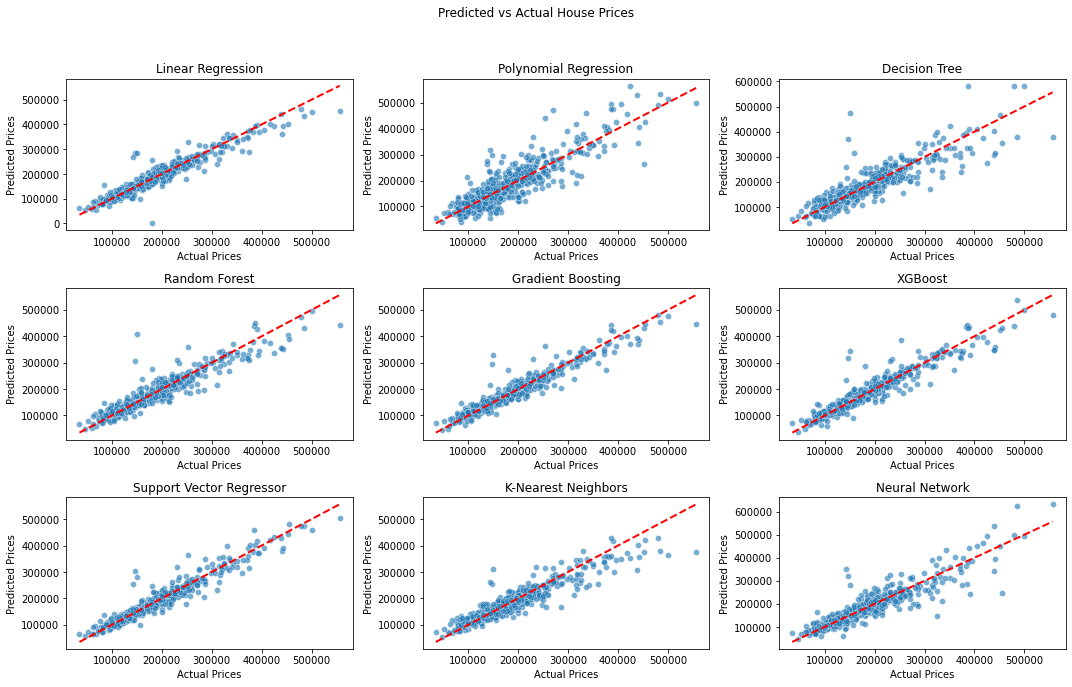

In [ ]:
# Plot Actual vs Predicted construction year after training
plt.figure(figsize=(15, 10))
plt.suptitle('Predicted vs Actual Construction Year')

# Target is not transformed, so we use the values directly
y_test_actual = y_test

# Create a subplot for each model's predictions
for i, (name, y_pred) in enumerate(trained_models.items(), 1):
    plt.subplot(3, 3, i)
    
    sns.scatterplot(x=y_test_actual, y=y_pred, alpha=0.6)
    plt.plot([y_test_actual.min(), y_test_actual.max()], [y_test_actual.min(), y_test_actual.max()], 'r--', lw=2)  # 45-degree line
    plt.xlabel('Actual Year Built')
    plt.ylabel('Predicted Year Built')
    plt.title(name)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


45-Degree Line (Red Dashed Line):

The red dashed line represents the "ideal" scenario where predictions exactly match the actual values.\
If a model performs perfectly, all points would lie on this line. Therefore, the closer the points are to this line, the better the modelâ€™s accuracy.

Scatter Spread:

Points close to the line indicate accurate predictions, where the modelâ€™s predictions closely match the actual house prices.\
Points farther from the line indicate less accurate predictions or errors. More scatter (larger spread) around the line suggests that the model struggles with accuracy, especially at certain price ranges.

Patterns of Bias:

If points are consistently above the line, the model is underpredicting (predicting values lower than actual).\
If points are consistently below the line, the model is overpredicting (predicting values higher than actual).

Breakdown of each plot:

Support Vector Regressor (bottom-left) and Gradient Boosting (top-right) seem to have the closest alignment to the red line, indicating strong performance in predicting house prices accurately.

Random Forest and XGBoost models also show good alignment but with slightly more dispersion compared to Gradient Boosting and SVR.

Linear Regression and Polynomial Regression show more variance around the red line, especially for higher price ranges, indicating potential underfitting for more complex patterns in the data.

K-Nearest Neighbors has some dispersion, but overall performance is reasonable for a simpler model.

Neural Network and Decision Tree models show moderate performance, with some deviations at higher price ranges.

In summary:

Support Vector Regressor, Gradient Boosting, XGBoost, and Random Forest appear to be the best-performing models.

The Linear Regression and Polynomial Regression models may be too simple for this dataset and show more prediction error at higher price points.

### Further Steps:

Hyperparameter Tuning: We will use techniques like Grid Search or Randomized Search to optimize hyperparameters for the best performing models (especially for Gradient Boosting and Support Vector Regressor).

Ensemble Methods: We will consider blending or stacking models for potentially better performance.

Feature Importance: Analyze feature importance in tree-based models to understand which features are most influential.

Final Model Selection: Finally, choose the best model based on application needs (accuracy, interpretability, computational cost).

We will perform tuning for Support Vector Regressor, Gradient Boosting, XGBoost, and Random Forest. Because they appear to be the best-performing models.

For radient Boosting and XGBoost models, we will perform Randomized Search. For others, we will perform Grid Search.

In [ ]:
# Define parameter grids for each model
param_grids = {
    'Random Forest': {
        'model__n_estimators': [50, 100, 200],
        'model__max_depth': [None, 10, 20, 30],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 2, 4]
    },
    'Gradient Boosting': {
        'model__n_estimators': [50, 100, 200],
        'model__learning_rate': [0.01, 0.1, 0.2],
        'model__max_depth': [3, 5, 7]
    },
    'XGBoost': {
        'model__n_estimators': [50, 100, 200],
        'model__learning_rate': uniform(0.01, 0.3),
        'model__max_depth': [3, 5, 7]
    },
    'Support Vector Regressor': {
        'model__kernel': ['linear', 'rbf'],
        'model__C': [0.1, 1, 10],
        'model__gamma': ['scale', 'auto']
    }
}

In [ ]:
# Define models to perform hyperparameter tuning
models = {
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42),
    'Support Vector Regressor': SVR()
}

# Dictionary to store the best models after tuning
best_models = {}

In [ ]:
# Perform hyperparameter tuning on each model with the pipeline
for name, model in models.items():
    print(f"Tuning {name}...")
    
    # Create pipeline with preprocessor and model
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    
    # Use either GridSearchCV or RandomizedSearchCV depending on the model
    if name in ['Random Forest', 'XGBoost']:
        search = RandomizedSearchCV(
            pipeline,
            param_distributions=param_grids[name],
            n_iter=10,
            cv=5,
            scoring='neg_mean_squared_error',
            n_jobs=-1,
            random_state=42
        )
    else:
        search = GridSearchCV(
            pipeline,
            param_grid=param_grids[name],
            cv=5,
            scoring='neg_mean_squared_error',
            n_jobs=-1
        )
    
    # Fit the search to the data
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    
    print(f"Best parameters for {name}: {search.best_params_}")
    print(f"Best RMSE for {name}: {np.sqrt(-search.best_score_):.4f}\n")

Tuning Random Forest...
Best parameters for Random Forest: {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_depth': None}
Best RMSE for Random Forest: 0.1308

Tuning Gradient Boosting...
Best parameters for Gradient Boosting: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
Best RMSE for Gradient Boosting: 0.1141

Tuning XGBoost...
Best parameters for XGBoost: {'model__learning_rate': 0.12236203565420874, 'model__max_depth': 3, 'model__n_estimators': 200}
Best RMSE for XGBoost: 0.1123

Tuning Support Vector Regressor...
Best parameters for Support Vector Regressor: {'model__C': 1, 'model__gamma': 'auto', 'model__kernel': 'rbf'}
Best RMSE for Support Vector Regressor: 0.1112



### Evaluation

In [ ]:
# evaluation matrix
# Evaluate each model on the test set
eval_matrix = []
for name, model in best_models.items():
    # Predict on the test set
    y_pred = model.predict(X_test)
    
    eval_matrix.append(evaluation_matrix(name, y_test, y_pred))

# Convert results to a DataFrame for better visualization
eval_matrix_df = pd.DataFrame(eval_matrix)
eval_matrix_df

,Model,Mean Absolute Error (MAE),Mean Squared Error,Root Mean Squared Error (RMSE),R-squared
0,Random Forest,0.093787,0.019062,0.138066,0.885442
1,Gradient Boosting,0.077987,0.013953,0.118122,0.916149
2,XGBoost,0.077195,0.013488,0.116139,0.918940
3,Support Vector Regressor,0.075941,0.012748,0.112906,0.923390
